# Проект «Анализ зарплат специалистов в области Data Science»

**Дисциплина:** «Методология анализа данных»

**Датасет:** [Data Science Job Salaries (Kaggle)](https://www.kaggle.com/datasets/ruchi798/data-science-job-salaries)

### Содержание
1. Введение и постановка цели
2. Предварительный обзор данных
3. Предобработка данных
4. Исследовательский анализ данных (EDA)
5. Визуализация данных
6. Прогнозирование и моделирование
7. Формулировка выводов

## 1. Введение и постановка цели

### 1.1. Описание датасета

Набор данных **Data Science Job Salaries** опубликован на Kaggle. Исходные данные собраны сервисом [ai-jobs.net](https://ai-jobs.net/salaries/), на котором специалисты в области данных сами, анонимно, заполняют анкету о своей зарплате. Период наблюдений - 2020-2022 годы.

Каждая строка — одна анкета. Структура данных:

| Признак | Описание | Тип |
|---|---|---|
| `work_year` | Год, за который указана зарплата | числовой |
| `experience_level` | Уровень опыта: `EN` — Entry-level/Junior, `MI` — Mid-level/Intermediate, `SE` — Senior/Expert, `EX` — Executive/Director | категориальный, порядковый |
| `employment_type` | Тип занятости: `PT` — частичная, `FT` — полная, `CT` — контракт, `FL` — фриланс | категориальный |
| `job_title` | Название должности | категориальный |
| `salary` | Годовая зарплата в местной валюте | числовой |
| `salary_currency` | Валюта зарплаты ISO 4217 | категориальный |
| `salary_in_usd` | Зарплата в долларах США | числовой |
| `employee_residence` | Страна проживания сотрудника ISO 3166 | категориальный |
| `remote_ratio` | Доля удалённой работы: `0` - офис (<20%), `50` — гибрид, `100` — полностью удалённо (>80%) | категориальный порядковый |
| `company_location` | Страна главного офиса / филиала работодателя ISO 3166 | категориальный |
| `company_size` | Размер компании: `S` — <50 сотрудников, `M` — 50–250, `L` — >250 | категориальный порядковый |

**Назначение данных:** сравнение уровня вознаграждения специалистов по данным в зависимости от опыта, должности, страны и формата работы.

### 1.2. Цель исследования

**Цель** - выявить **топ-3 фактора**, сильнее всего влияющих на годовую зарплату специалиста в области данных, и количественно оценить их влияние, например разницу медианных зарплат между группами, статистическую значимость, вклад признака в прогнозную модель.

Результаты могут быть полезны:
- **работодателю / HR** - для формирования конкурентной вилки зарплат при найме.
- **соискателю** - чтобы понимать, от чего зависит его рыночная стоимость и куда расти.

### 1.3. Исследовательские задачи

1. Загрузить данные и провести первичный обзор: размер, типы, пропуски, дубликаты, базовые статистики.
2. Выполнить предобработку: обработать дубликаты, удалить избыточные столбцы, проанализировать выбросы, сконструировать новые признаки.
3. Изучить распределение зарплат, проверить его на нормальность.
4. Провести корреляционный анализ и сравнить зарплаты в разрезе опыта, размера компании, формата работы, региона и должности; проверить гипотезы статистическими тестами.
5. Проверить наличие временной динамики роста зарплат с 2020-2022, отделить реальный рост от изменения структуры выборки.
6. Построить и сравнить модели прогнозирования зарплаты, оценить важность признаков.
7. Сформулировать выводы, рекомендации и ограничения исследования.

### 1.4. Гипотезы

| № | Гипотеза |
|---|---|
| **H1** | Зарплата монотонно растёт с уровнем опыта: EN < MI < SE < EX | 
| **H2** | Компании, расположенные в США, платят больше, чем компании из других стран | 
| **H3** | В малых компаниях (S) зарплаты ниже, чем в средних (M) и крупных (L) | 
| **H4** | Полностью удалённые сотрудники получают не меньше, чем офисные и работающие в формате "гибрид" | 
| **H5** | Рост запралт с 2020 по 2022 год | м
| **H6** | Руководящие и ML/AI-должности оплачиваются выше, чем аналитические | 


In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

# Единый стиль графиков для всего проекта
sns.set_theme(style='whitegrid', palette='deep', font_scale=1.0)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titleweight'] = 'bold'
MAIN_COLOR = sns.color_palette('deep')[0]
ACCENT_COLOR = sns.color_palette('deep')[3]

# Форматтер оси: 100000 -> "100k"
usd_fmt = mticker.FuncFormatter(lambda x, _: f'{x/1000:.0f}k')

RANDOM_STATE = 42

## 2. Предварительный обзор данных

### 2.1. Происхождение данных.

- **Откуда данные:** агрегатор вакансий ai-jobs.net.
- **Как собирались:** добровольный анонимный опрос - респондент сам указывает должность, зарплату, страну и т.д.

### 2.2. Загрузка данных

In [3]:
df_raw = pd.read_csv('ds_salaries.csv')
df_raw.head(10)

,Unnamed: 0,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L
1,1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S
2,2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,50,GB,M
3,3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,0,HN,S
4,4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,50,US,L
5,5,2020,EN,FT,Data Analyst,72000,USD,72000,US,100,US,L
6,6,2020,SE,FT,Lead Data Scientist,190000,USD,190000,US,100,US,S
7,7,2020,MI,FT,Data Scientist,11000000,HUF,35735,HU,50,HU,L
8,8,2020,MI,FT,Business Data Analyst,135000,USD,135000,US,100,US,L
9,9,2020,SE,FT,Lead Data Engineer,125000,USD,125000,NZ,50,NZ,S


Первый столбец `Unnamed: 0` - это сохранённый при экспорте индекс строк, он не несёт информации. Укажем его как индекс при чтении.

In [4]:
df = pd.read_csv('ds_salaries.csv', index_col=0)
print(f'Строк: {df.shape[0]}, столбцов: {df.shape[1]}')
df.info()

Строк: 607, столбцов: 11
<class 'pandas.core.frame.DataFrame'>
Index: 607 entries, 0 to 606
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           607 non-null    int64 
 1   experience_level    607 non-null    object
 2   employment_type     607 non-null    object
 3   job_title           607 non-null    object
 4   salary              607 non-null    int64 
 5   salary_currency     607 non-null    object
 6   salary_in_usd       607 non-null    int64 
 7   employee_residence  607 non-null    object
 8   remote_ratio        607 non-null    int64 
 9   company_location    607 non-null    object
 10  company_size        607 non-null    object
dtypes: int64(4), object(7)
memory usage: 56.9+ KB


**Типы данных соответствуют содержанию:** 4 целочисленных столбца и 7 текстовых типа `object`. Приводить типы принудительно не требуется, однако порядковые признаки для`experience_level`, `company_size`, `remote_ratio` в дальнейшем удобно перевести в упорядоченные категории.

In [5]:
# Количество уникальных значений в каждом столбце
df.nunique().to_frame('уникальных значений')

,уникальных значений
work_year,3
experience_level,4
employment_type,4
job_title,50
salary,272
salary_currency,17
salary_in_usd,369
employee_residence,57
remote_ratio,3
company_location,50


In [6]:
# Уникальные значения категориальных признаков с небольшим числом категорий
for col in ['work_year', 'experience_level', 'employment_type', 'remote_ratio', 'company_size']:
    print(f'{col}: {df[col].value_counts().to_dict()}')

work_year: {2022: 318, 2021: 217, 2020: 72}
experience_level: {'SE': 280, 'MI': 213, 'EN': 88, 'EX': 26}
employment_type: {'FT': 588, 'PT': 10, 'CT': 5, 'FL': 4}
remote_ratio: {100: 381, 0: 127, 50: 99}
company_size: {'M': 326, 'L': 198, 'S': 83}


### 2.3. Проверка на наличие пропусковв и дубликатов

Перед проверкой я удаляю столбец `salary`. В данных два столбца с зарплатой: `salary` в местной валюте и `salary_in_usd` в долларах США. `salary_in_usd` получен из `salary` пересчётом по среднегодовому курсу, поэтому столбцы несут одну и ту же информацию. `salary_in_usd` уже приведён к одной валюте, и сравнивать зарплаты можно без пересчёта по курсу. Также удалим столбец тип валюты `salary_currency`, потому что после удаления столбца `salary`, ценности данный столбец не представляет.


In [7]:
df = df.drop(columns=['salary', "salary_currency"])
print(f'Столбцов после удаления столбцов: {df.shape[1]}')
print('Пропущенных значений по столбцам:')
print(df.isna().sum())
print(f'\nПолных дубликатов строк: {df.duplicated().sum()} ({df.duplicated().mean():.1%} от выборки)')

Столбцов после удаления столбцов: 9
Пропущенных значений по столбцам:
work_year             0
experience_level      0
employment_type       0
job_title             0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64

Полных дубликатов строк: 42 (6.9% от выборки)


### 2.4. Базовые статистики для целевой переменной

In [8]:
num_stats = df[['salary_in_usd']].agg(['count', 'mean', 'median', 'std', 'min', 'max']).T
num_stats['mean/median'] = num_stats['mean'] / num_stats['median']
num_stats.round(1)


,count,mean,median,std,min,max,mean/median
salary_in_usd,607.0,112297.9,101570.0,70957.3,2859.0,600000.0,1.1


In [9]:
df.describe(include='object')

,experience_level,employment_type,job_title,employee_residence,company_location,company_size
count,607,607,607,607,607,607
unique,4,4,50,57,50,3
top,SE,FT,Data Scientist,US,US,M
freq,280,588,143,332,355,326


### 2.5. Первичные визуализации

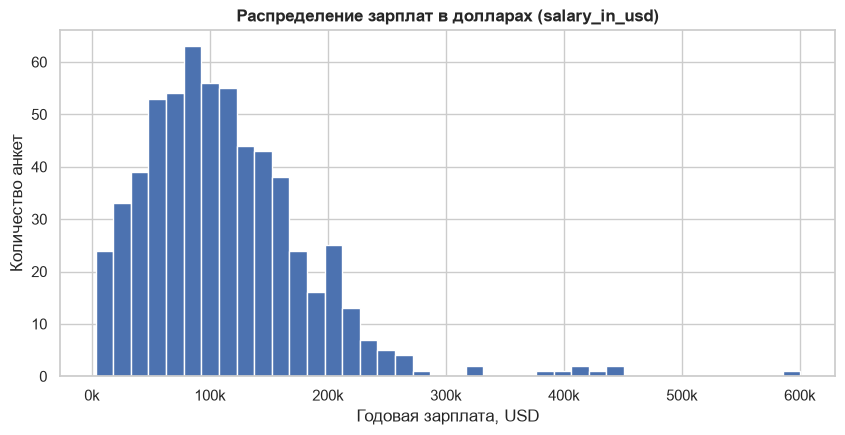

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(df['salary_in_usd'], bins=40, color=MAIN_COLOR, edgecolor='white')
ax.set_title('Распределение зарплат в долларах (salary_in_usd)')
ax.set_xlabel('Годовая зарплата, USD')
ax.set_ylabel('Количество анкет')
ax.xaxis.set_major_formatter(usd_fmt)
plt.show()


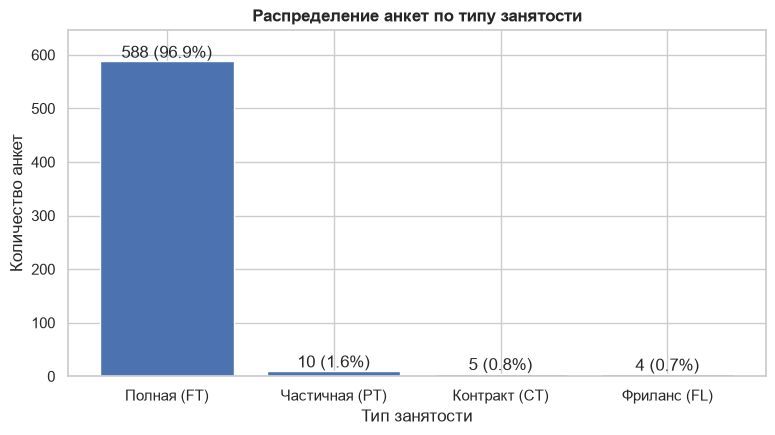

In [11]:
EMP_LABELS = {'FT': 'Полная (FT)', 'PT': 'Частичная (PT)', 'CT': 'Контракт (CT)', 'FL': 'Фриланс (FL)'}
counts = df['employment_type'].value_counts().rename(index=EMP_LABELS)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(counts.index, counts.values, color=MAIN_COLOR)
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v} ({v / counts.sum():.1%})', ha='center', va='bottom')
ax.set_title('Распределение анкет по типу занятости')
ax.set_xlabel('Тип занятости')
ax.set_ylabel('Количество анкет')
ax.set_ylim(0, counts.max() * 1.1)
plt.show()


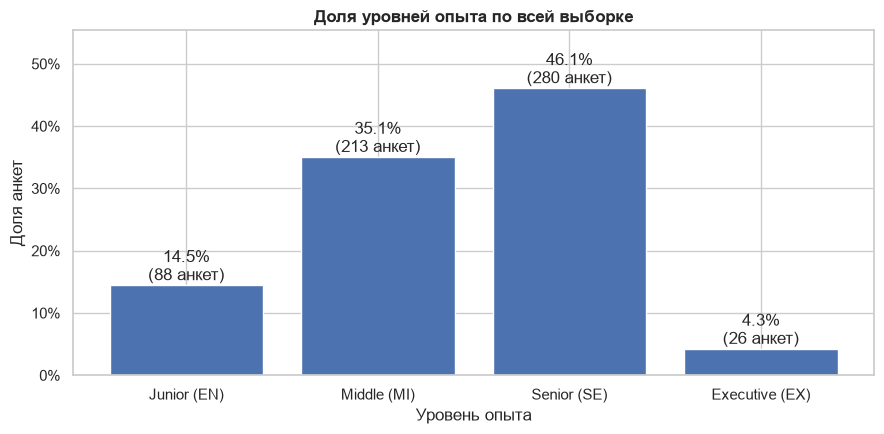

In [13]:
exp_share = df['experience_level'].value_counts(normalize=True).reindex(['EN', 'MI', 'SE', 'EX'])
exp_share.index = ['Junior (EN)', 'Middle (MI)', 'Senior (SE)', 'Executive (EX)']
exp_count = df['experience_level'].value_counts().reindex(['EN', 'MI', 'SE', 'EX'])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(exp_share.index, exp_share.values, color=MAIN_COLOR)
for i, (share, n) in enumerate(zip(exp_share.values, exp_count.values)):
    ax.text(i, share, f'{share:.1%}\n({n} анкет)', ha='center', va='bottom')
ax.set_title('Доля уровней опыта по всей выборке')
ax.set_xlabel('Уровень опыта')
ax.set_ylabel('Доля анкет')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylim(0, exp_share.max() * 1.2)
plt.tight_layout()
plt.show()


### Выводы по предварительному обзору

- В данных **607 строк и 9 содержательных столбцов**.
- **Пропусков нет**.
- Найдено **42 полных дубликата** (≈7% выборки).
- Столбец `salary` **несопоставим между строками** из-за разных валют. 300 тысяч евро != 300 тысяч рупий. Для анализа используем только `salary_in_usd`.
- Распределение `salary_in_usd` **сильно скошено вправо**: среднее (~112 тыс.) больше медианы (~101 тыс.), длинный хвост до 600 тыс. USD. Поэтому в дальнейшем для сравнения групп опираемся на **медианы**. Зарплаты очень разняться от `min=2859$` до `max=600000$`.
- Выборка несбалансирована по типу занятости: 96,9% находятся на полной занятости (`FT`).
- Больше всего анкет с уровнем опыта Senior `SE`. Можно предположить, что агрегатором вакансий ai-jobs.net пользуются компании для поиска DS-инженеров с достаточно большим опытом уровня Middle, Senior для высоких позиций.

## 3. Предобработка данных



In [14]:
# В какие годы попадают дубликаты
df[df.duplicated()]['work_year'].value_counts().sort_index()

work_year
2021     2
2022    40
Name: count, dtype: int64

**Решение: удаляем дубликаты.**

Обоснование:
- в датасете нет идентификатора респондента, поэтому формально два разных человека могут иметь одинаковые параметры. Но совпадение **всех 11 полей**, включая точную зарплату в местной валюте, для разных людей маловероятно.
- все дубликаты относятся к 2022 году - самому свежему периоду, когда на сайт поступало больше всего анкет. Возоможно это повторная отправка формы или повторная выгрузка записей.


In [15]:
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Было строк: {n_before}, удалено: {n_before - len(df)}, осталось: {len(df)}')

Было строк: 607, удалено: 42, осталось: 565


### 3.4. Выбросы

Проверим выбросы в целевой переменной `salary_in_usd` по правилу межквартильного размаха (IQR). Выбросом считаем значение вне интервала $[Q_1 - 1.5\cdot IQR;\ Q_3 + 1.5\cdot IQR]$.

In [16]:
q1, q3 = df['salary_in_usd'].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df['salary_in_usd'] < low) | (df['salary_in_usd'] > high)]
print(f'Q1 = {q1:,.0f}, Q3 = {q3:,.0f}, IQR = {iqr:,.0f}')
print(f'Границы: [{low:,.0f}; {high:,.0f}]')
print(f'Выбросов: {len(outliers)}')
outliers.sort_values('salary_in_usd', ascending=False)

Q1 = 60,757, Q3 = 150,000, IQR = 89,243
Границы: [-73,108; 283,864]
Выбросов: 10


,work_year,experience_level,employment_type,job_title,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
251,2021,EX,FT,Principal Data Engineer,600000,US,100,US,L
33,2020,MI,FT,Research Scientist,450000,US,0,US,M
97,2021,MI,FT,Financial Data Analyst,450000,US,100,US,L
157,2021,MI,FT,Applied Machine Learning Scientist,423000,US,50,US,L
224,2021,EX,CT,Principal Data Scientist,416000,US,100,US,S
63,2020,SE,FT,Data Scientist,412000,US,100,US,L
502,2022,SE,FT,Data Analytics Lead,405000,US,100,US,L
498,2022,SE,FT,Applied Data Scientist,380000,US,100,US,L
25,2020,EX,FT,Director of Data Science,325000,US,100,US,L
461,2022,EX,FT,Data Engineer,324000,US,100,US,M


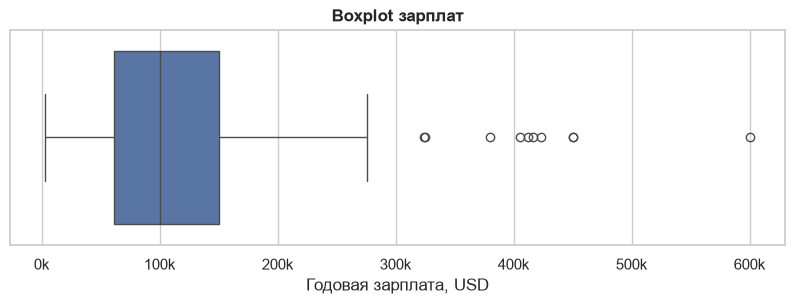

In [17]:
fig, ax = plt.subplots(figsize=(10, 2.8))
sns.boxplot(x=df['salary_in_usd'], color=MAIN_COLOR, ax=ax)
ax.set_title('Boxplot зарплат')
ax.set_xlabel('Годовая зарплата, USD')
ax.xaxis.set_major_formatter(usd_fmt)
plt.show()

In [18]:
outliers['company_location'].value_counts().to_frame('количество анкет')


,количество анкет
company_location,
US,10


In [19]:
outliers['experience_level'].value_counts().to_frame('количество анкет')


,количество анкет
experience_level,
EX,4
MI,3
SE,3


**Итоги: верхние выбросы не удалять
Обоснование:
**Все 10 верхних выбросов (>284 тыс. USD) - компании из США**, позиции уровня Senior/Executive и «Principal», «Director», «Head», «Research Scientist». Для американского рынка такие зарплаты реалистичны, это верхний сегмент рынка.

## Поработаем с 30 самыми низкими зарплатами из датасета

In [20]:
low30 = df.nsmallest(30, 'salary_in_usd')
print(f"Верхняя граница 30 самых низких зарплат: {low30['salary_in_usd'].max():,} USD")

low_countries = pd.DataFrame({
    'по стране компании': low30['company_location'].value_counts(normalize=True),
    'по стране сотрудника': low30['employee_residence'].value_counts(normalize=True),
}).fillna(0).sort_values(['по стране компании', 'по стране сотрудника'], ascending=False)
display(low_countries.style
        .format('{:.1%}')
        .set_caption('Доля стран среди 30 самых низких зарплат'))

display(low30.loc[low30['company_location'] == 'US',
                  ['job_title', 'experience_level', 'salary_in_usd', 'employee_residence']].style
        .set_caption('Анкеты компаний из США среди 30 самых низких зарплат'))


Верхняя граница 30 самых низких зарплат: 19,609 USD


,по стране компании,по стране сотрудника
IN,33.3%,43.3%
US,10.0%,0.0%
BR,6.7%,10.0%
PK,6.7%,10.0%
DE,3.3%,3.3%
ES,3.3%,3.3%
IR,3.3%,3.3%
KE,3.3%,3.3%
MD,3.3%,3.3%
MX,3.3%,3.3%


,job_title,experience_level,salary_in_usd,employee_residence
179,Data Scientist,MI,5679,IN
96,AI Scientist,EN,12000,BR
113,AI Scientist,EN,12000,PK


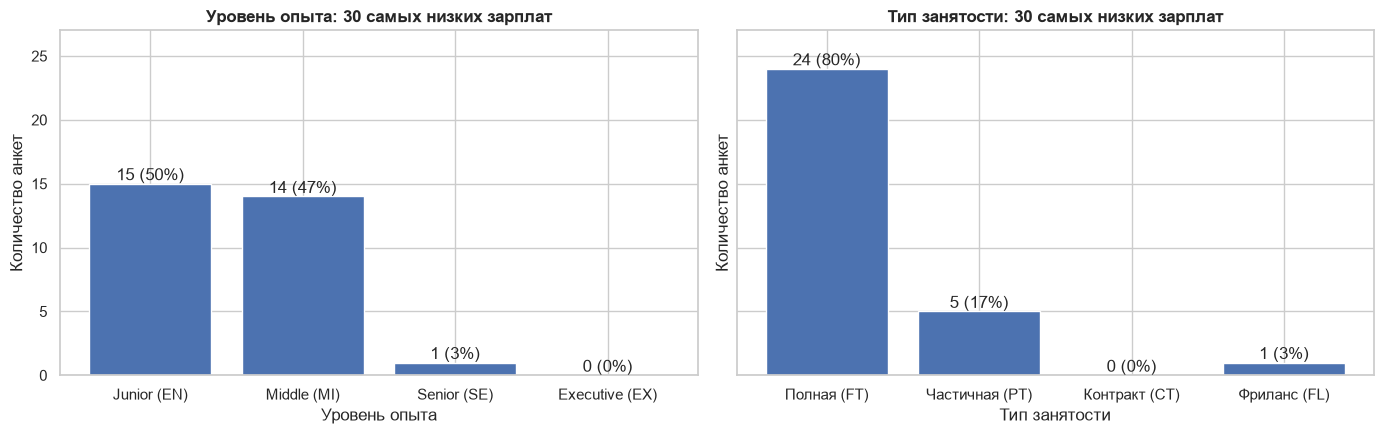

In [21]:
exp = low30['experience_level'].value_counts().reindex(['EN', 'MI', 'SE', 'EX'], fill_value=0)
exp.index = ['Junior (EN)', 'Middle (MI)', 'Senior (SE)', 'Executive (EX)']
emp = low30['employment_type'].value_counts().reindex(['FT', 'PT', 'CT', 'FL'], fill_value=0)
emp.index = ['Полная (FT)', 'Частичная (PT)', 'Контракт (CT)', 'Фриланс (FL)']

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, counts, title in [(axes[0], exp, 'Уровень опыта'), (axes[1], emp, 'Тип занятости')]:
    ax.bar(counts.index, counts.values, color=MAIN_COLOR)
    for i, v in enumerate(counts.values):
        ax.text(i, v, f'{v} ({v / len(low30):.0%})', ha='center', va='bottom')
    ax.set_title(f'{title}: 30 самых низких зарплат')
    ax.set_xlabel(title)
    ax.set_ylabel('Количество анкет')
axes[0].set_ylim(0, len(low30) * 0.9)
plt.tight_layout()
plt.show()


**Вывод по 30 самым низким зарплатам**

Самые низкие `30` зарплат не превышают `19 609` USD в год. Их объясняют три причины: страна проживания сотрудника, небольшой опыт и неполная ставка.

- Страна. Треть анкет приходится на компании из Индии, `33.3%`, а по стране проживания доля Индии ещё выше, `43.3%`. Следом идут Бразилия и Пакистан, по `10%` по стране проживания. Остальные `14` стран встречаются по одному разу.
- Компании США. На них приходится `3` анкеты, `10%`, но ни один из этих сотрудников не живёт в США. Это Middle из Индии с `5 679` USD и два Junior из Бразилии и Пакистана с `12 000` USD, которые работают на американскую компанию удалённо. Размер зарплат в США **скорее всего** больше определяется страной проживания сотрудника. (Дешёвый рабочий труд)
- Опыт. Почти все анкеты уровня Junior и Middle: `15` и `14`. Senior `1` Доля Junior среди низких зарплат `50%` против `16%` во всей выборке.
- Тип занятости. Частичная занятость составляет `17%` низких зарплат против `1.8%` во всей выборке. Часть сумм скорее всего мала из-за неполной ставки. При этом `80%` анкет составляют **полная занятость**, то есть низкая зарплата встречается и на полной ставке.

**Вывод:**

Эти зарплаты соответствуют уровню зарплат в странах проживания и начальным позициям.


### 3.5. Новые признаки

1. **`job_category`** - укрупнённая категория должностей категории `job_title`. 50 названий в свободной форме. Анализировать их по отдельности статистически бессмысленно при наличии всего 565 объектов после чистки. Группируем по ключевым словам:
   - *Руководство* - Manager, Director, Head;
   - *ML / AI* - Machine Learning, ML, AI, Computer Vision, NLP.
   - *Исследования* - Research.
   - *Аналитика* - Analyst, Analytics, BI.
   - *Data Science* - Scientist, Science, Specialist.
   - *Data Engineering* - Engineer, Architect, ETL, Developer.
2. **`company_region`** — регион компании: *США*, *Европа*, *Остальной мир* (57 стран сжимаем до 3 устойчивых групп).
3. **`is_us_company`** — бинарный признак «компания из США» (1/0) для корреляционного анализа.
4. **`abroad`** — сотрудник живёт не в той стране, где находится компания.
5. **`exp_level_num`**, **`company_size_num`** — порядковые кодировки опыта (1–4) и размера компании (1–3).
6. **`log_salary`** - натуральный логарифм зарплаты.
7. Добавить дополнительные подписи для уровня опыта, размер компании, уровень удалёнки.

In [22]:
def job_category(title: str) -> str:
    t = title.lower()
    if any(k in t for k in ['manager', 'director', 'head']):
        return 'Руководство'
    if any(k in t for k in ['machine learning', 'ml ', 'ai ', 'computer vision', 'nlp']) or t.startswith('ml'):
        return 'ML / AI'
    if 'research' in t:
        return 'Исследования'
    if any(k in t for k in ['analyst', 'analytics', 'bi ']):
        return 'Аналитика'
    if any(k in t for k in ['scientist', 'science', 'specialist']):
        return 'Data Science'
    return 'Data Engineering'

df['job_category'] = df['job_title'].apply(job_category)

# Проверка разметки
(df.groupby('job_category')['job_title']
   .agg(lambda s: ', '.join(s.value_counts().index))
   .to_frame('должности'))

,должности
job_category,
Data Engineering,"Data Engineer, Data Architect, Big Data Engine..."
Data Science,"Data Scientist, Data Science Consultant, Princ..."
ML / AI,"Machine Learning Engineer, Machine Learning Sc..."
Аналитика,"Data Analyst, BI Data Analyst, Business Data A..."
Исследования,Research Scientist
Руководство,"Data Science Manager, Director of Data Science..."


In [23]:
EUROPE = {'AT', 'BE', 'BG', 'CH', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GB', 'GR', 'HR', 'HU',
          'IE', 'IT', 'LU', 'MD', 'MT', 'NL', 'NO', 'PL', 'PT', 'RO', 'RS', 'RU', 'SE', 'SI', 'UA'}

def region(code: str) -> str:
    if code == 'US':
        return 'США'
    return 'Европа' if code in EUROPE else 'Остальной мир'

df['company_region'] = df['company_location'].apply(region)
df['is_us_company'] = (df['company_location'] == 'US').astype(int)
df['abroad'] = (df['employee_residence'] != df['company_location']).astype(int)

EXP_ORDER = ['EN', 'MI', 'SE', 'EX']
SIZE_ORDER = ['S', 'M', 'L']
df['exp_level_num'] = df['experience_level'].map({k: i + 1 for i, k in enumerate(EXP_ORDER)})
df['company_size_num'] = df['company_size'].map({k: i + 1 for i, k in enumerate(SIZE_ORDER)})
df['log_salary'] = np.log(df['salary_in_usd'])

# Подписи для графиков
EXP_LABELS = {'EN': 'Junior (EN)', 'MI': 'Middle (MI)', 'SE': 'Senior (SE)', 'EX': 'Executive (EX)'}
SIZE_LABELS = {'S': 'Малая (S)', 'M': 'Средняя (M)', 'L': 'Крупная (L)'}
REMOTE_LABELS = {0: 'Офис (0%)', 50: 'Гибрид (50%)', 100: 'Удалённо (100%)'}
df['experience'] = pd.Categorical(df['experience_level'].map(EXP_LABELS), [EXP_LABELS[k] for k in EXP_ORDER], ordered=True)
df['size'] = pd.Categorical(df['company_size'].map(SIZE_LABELS), [SIZE_LABELS[k] for k in SIZE_ORDER], ordered=True)
df['remote'] = pd.Categorical(df['remote_ratio'].map(REMOTE_LABELS), list(REMOTE_LABELS.values()), ordered=True)

print(df['company_region'].value_counts().to_dict())
print(df['job_category'].value_counts().to_dict())
print(f"Работают на компанию из другой страны: {df['abroad'].sum()} ({df['abroad'].mean():.1%})")
df.head()

{'США': 318, 'Европа': 154, 'Остальной мир': 93}
{'Data Science': 157, 'Data Engineering': 153, 'Аналитика': 113, 'ML / AI': 82, 'Руководство': 44, 'Исследования': 16}
Работают на компанию из другой страны: 51 (9.0%)


,work_year,experience_level,employment_type,job_title,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,job_category,company_region,is_us_company,abroad,exp_level_num,company_size_num,log_salary,experience,size,remote
0,2020,MI,FT,Data Scientist,79833,DE,0,DE,L,Data Science,Европа,0,0,2,3,11.287692,Middle (MI),Крупная (L),Офис (0%)
1,2020,SE,FT,Machine Learning Scientist,260000,JP,0,JP,S,ML / AI,Остальной мир,0,0,3,1,12.468437,Senior (SE),Малая (S),Офис (0%)
2,2020,SE,FT,Big Data Engineer,109024,GB,50,GB,M,Data Engineering,Европа,0,0,3,2,11.599323,Senior (SE),Средняя (M),Гибрид (50%)
3,2020,MI,FT,Product Data Analyst,20000,HN,0,HN,S,Аналитика,Остальной мир,0,0,2,1,9.903488,Middle (MI),Малая (S),Офис (0%)
4,2020,SE,FT,Machine Learning Engineer,150000,US,50,US,L,ML / AI,США,1,0,3,3,11.918391,Senior (SE),Крупная (L),Гибрид (50%)


## 4. Исследовательский анализ данных (EDA)

Цель данной главы: 

Провести корреляционный анализ и сравнить зарплаты в разрезе опыта, размера компании, формата работы, региона и должности; проверить гипотезы статистическими тестами.


### 4.1. Распределение целевой переменной и проверка нормальности

In [24]:
s = df['salary_in_usd']
print(f"Среднее:     {s.mean():>10,.0f} USD")
print(f"Медиана:     {s.median():>10,.0f} USD")
print(f"Ст. откл.:   {s.std():>10,.0f} USD")
print(f"Асимметрия: {s.skew():.2f}")
print(f"Эксцесс:    {s.kurt():.2f}")

for name, x in [('salary_in_usd', s), ('log(salary_in_usd)', df['log_salary'])]:
    w, p = stats.shapiro(x)
    print(f'Тест Шапиро–Уилка для {name}: W = {w:.3f}, p-value = {p:.2e}')

Среднее:        110,610 USD
Медиана:        100,000 USD
Ст. откл.:       72,281 USD
Асимметрия: 1.73
Эксцесс:    6.45
Тест Шапиро–Уилка для salary_in_usd: W = 0.891, p-value = 1.36e-19
Тест Шапиро–Уилка для log(salary_in_usd): W = 0.926, p-value = 4.53e-16


Тест Шапиоро-Уилка используется для проверки, что выборка распределена по нормальному закону.

H_{0} - данные взяты из нормального распределения

H_{1} - распредеелние данных не является нормальным.

p-value > 0.05 - нет основанией отвергать H_{0}.

p-value <= 0.05 - отвергаем H_{0} в пользу H_{1}.

Логарифмирование берём для того, чтобы убрать скошенность. 

**Вывод:** p-value < 0.05, как для salary_in_usd, так и для log(salary_in_usd), поэтому мы отвергаем гипотезу H_{0}.

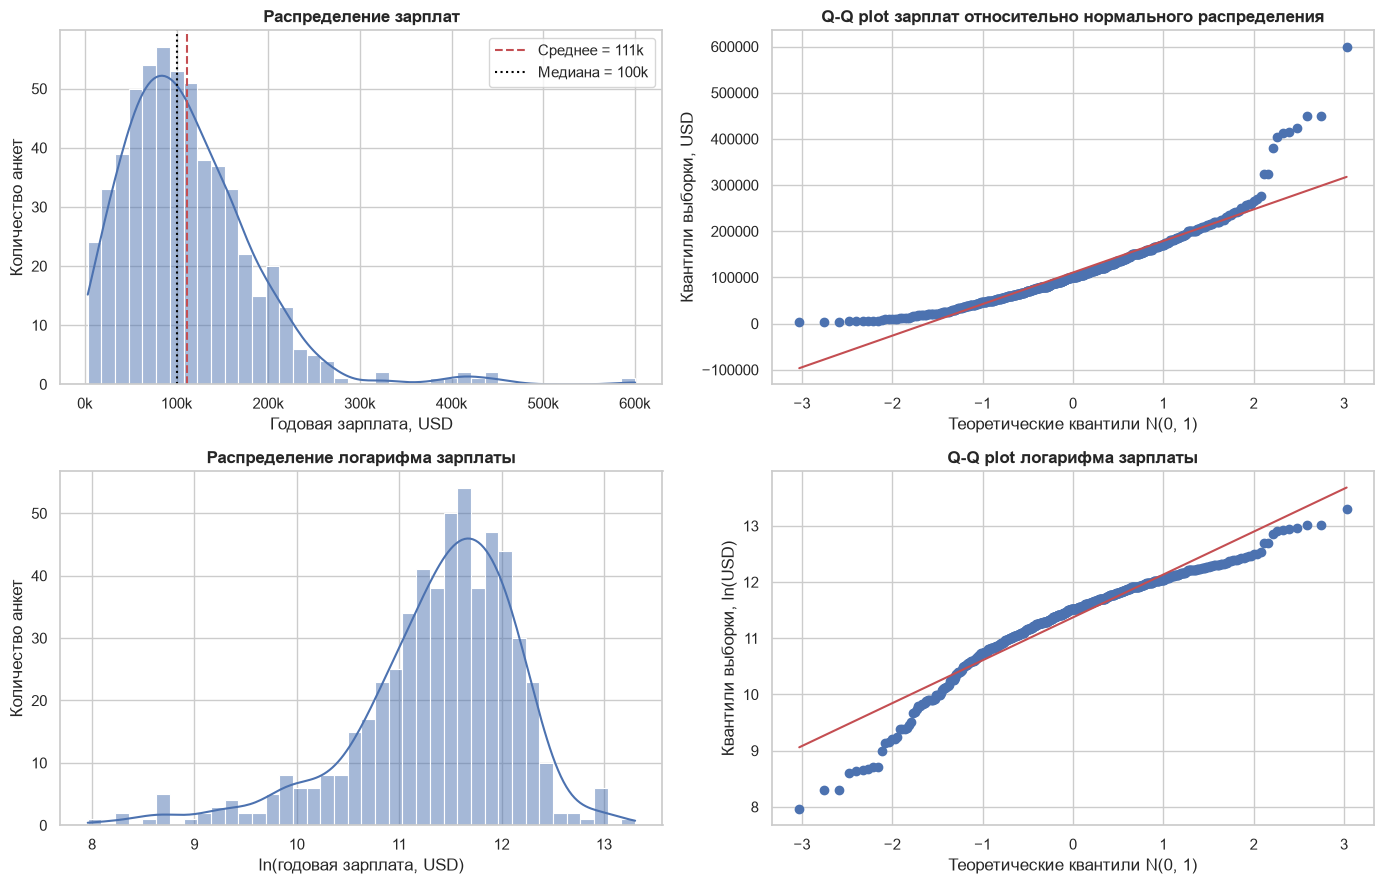

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(s, bins=40, kde=True, color=MAIN_COLOR, ax=axes[0, 0])
axes[0, 0].axvline(s.mean(), color=ACCENT_COLOR, ls='--', label=f'Среднее = {s.mean()/1000:.0f}k')
axes[0, 0].axvline(s.median(), color='black', ls=':', label=f'Медиана = {s.median()/1000:.0f}k')
axes[0, 0].set_title('Распределение зарплат')
axes[0, 0].set_xlabel('Годовая зарплата, USD')
axes[0, 0].set_ylabel('Количество анкет')
axes[0, 0].xaxis.set_major_formatter(usd_fmt)
axes[0, 0].legend()

stats.probplot(s, dist='norm', plot=axes[0, 1])
axes[0, 1].set_title('Q-Q plot зарплат относительно нормального распределения')
axes[0, 1].set_xlabel('Теоретические квантили N(0, 1)')
axes[0, 1].set_ylabel('Квантили выборки, USD')

sns.histplot(df['log_salary'], bins=40, kde=True, color=MAIN_COLOR, ax=axes[1, 0])
axes[1, 0].set_title('Распределение логарифма зарплаты')
axes[1, 0].set_xlabel('ln(годовая зарплата, USD)')
axes[1, 0].set_ylabel('Количество анкет')

stats.probplot(df['log_salary'], dist='norm', plot=axes[1, 1])
axes[1, 1].set_title('Q-Q plot логарифма зарплаты')
axes[1, 1].set_xlabel('Теоретические квантили N(0, 1)')
axes[1, 1].set_ylabel('Квантили выборки, ln(USD)')

plt.tight_layout()
plt.show()

**Описание распределения:**
- Распределение `salary_in_usd` **унимодальное, правосторонне-асимметричное**  с тяжёлым правым хвостом: основная масса зарплат 60–150 тыс. USD, но есть редкие значения до 600 тыс. USD. На Q-Q plot точки правого хвоста уходят вверх от прямой.
- Тест Шапиро–Уилка отвергает нормальность распределения.
- После логарифмирования правый хвост исчезает, но появляется **левый хвост** - анкеты из стран с низкими зарплатами 2–20 тыс. USD. Нормальность формально также отвергается, однако распределение становится более симметричным.

**Методологическое обоснование выбора статичестических инструментов:** Так как данные из не нормального распределения, не нормированы так скажем, то в качестве статистических инструментов используем **непараметрические** тесты - Манна–Уитни для 2 групп и Краскела–Уоллиса для 3 и более групп, а для корреляций - коэффициент ранговой корреляции Спирмена.

### 4.2. Распределения категориальных признаков

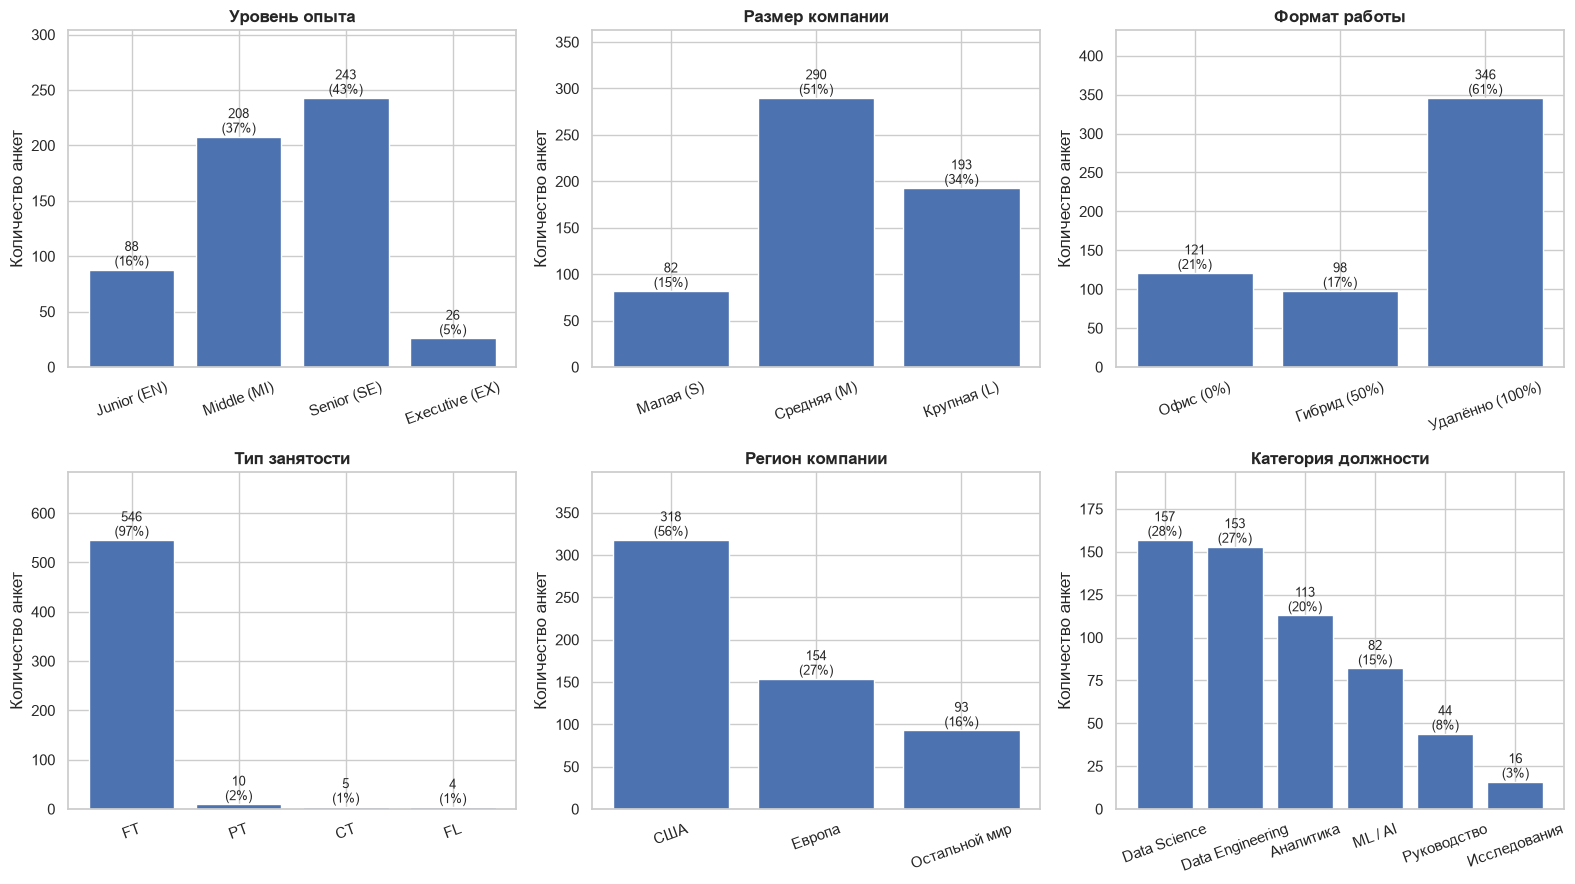

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
plots = [
    ('experience', 'Уровень опыта'),
    ('size', 'Размер компании'),
    ('remote', 'Формат работы'),
    ('employment_type', 'Тип занятости'),
    ('company_region', 'Регион компании'),
    ('job_category', 'Категория должности'),
]
for ax, (col, title) in zip(axes.flat, plots):
    vc = df[col].value_counts(sort=col not in ('experience', 'size', 'remote')).sort_index() \
        if col in ('experience', 'size', 'remote') else df[col].value_counts()
    ax.bar(vc.index.astype(str), vc.values, color=MAIN_COLOR)
    for i, v in enumerate(vc.values):
        ax.text(i, v, f'{v}\n({v/len(df):.0%})', ha='center', va='bottom', fontsize=9)
    ax.set_title(title)
    ax.set_ylabel('Количество анкет')
    ax.set_ylim(0, vc.max() * 1.25)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

- Senior и Middle дают `43%` и `37%` анкет, Executive - `26` анкет, Junior - `88` анкет.
- Полная занятость - `97%` анкет. В группах PT, CT, FL от `4` до `10` анкет, поэтому тип занятости я дальше не сравниваю.
- Компании из США - `56%` анкет, полностью удалённая работа - `61%`.

### 4.3. Оставшиеся выбросы внутри групп


In [27]:
def iqr_low(g):
    q1, q3 = g.quantile([0.25, 0.75])
    return (g < q1 - 1.5 * (q3 - q1)).sum()

def iqr_high(g):
    q1, q3 = g.quantile([0.25, 0.75])
    return (g > q3 + 1.5 * (q3 - q1)).sum()

out_by_exp = df.groupby('experience', observed=True)['salary_in_usd'].agg(['count', 'median', iqr_low, iqr_high])
out_by_exp.columns = ['анкет', 'медиана, USD', 'выбросов снизу', 'выбросов сверху']
out_by_exp


,анкет,"медиана, USD",выбросов снизу,выбросов сверху
experience,,,,
Junior (EN),88,56500.0,0,2
Middle (MI),208,76940.0,0,5
Senior (SE),243,135000.0,0,3
Executive (EX),26,171437.5,0,2


Внутри групп общая сумма выбросов составило `12` анкет, все сверху. Это высокие зарплаты, которые объясняются сочетанием опыта и страны компании, поэтому я их не удаляю.

### 4.4. Корреляционный анализ

Количественный признак в данных один, зарплата. Матрицу я строю по порядковым и бинарным кодировкам остальных признаков.


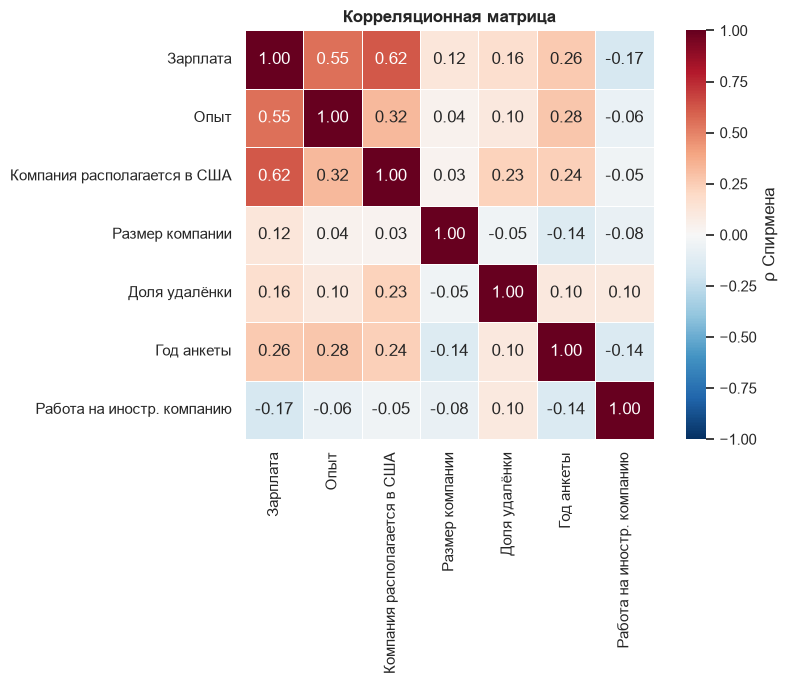

In [28]:
corr_cols = {
    'salary_in_usd': 'Зарплата',
    'exp_level_num': 'Опыт',
    'is_us_company': 'Компания располагается в США',
    'company_size_num': 'Размер компании',
    'remote_ratio': 'Доля удалёнки',
    'work_year': 'Год анкеты',
    'abroad': 'Работа на иностр. компанию',
}
corr = df[list(corr_cols)].rename(columns=corr_cols).corr(method='spearman')

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'label': 'ρ Спирмена'}, ax=ax)
ax.set_title('Корреляционная матрица')
plt.tight_layout()
plt.show()

Имеется коррелляция между `Зарплатой-Опытом`, `Зарплатой-Компания располагается в США`

In [29]:
# Значимость корреляций признаков с зарплатой
rows = []
for col, label in list(corr_cols.items())[1:]:
    rho, p = stats.spearmanr(df[col], df['salary_in_usd'])
    rows.append({'признак': label, 'ρ Спирмена': round(rho, 3), 'ρ-value': f'{p:.1e}', 'статистически значимо при α=0.05': p < 0.05})
pd.DataFrame(rows).sort_values('ρ Спирмена', key=abs, ascending=False).reset_index(drop=True)

,признак,ρ Спирмена,ρ-value,статистически значимо при α=0.05
0,Компания располагается в США,0.618,9.0e-61,True
1,Опыт,0.552,2.3e-46,True
2,Год анкеты,0.260,3.6e-10,True
3,Работа на иностр. компанию,-0.169,5.4e-05,True
4,Доля удалёнки,0.164,8.9e-05,True
5,Размер компании,0.120,4.1e-03,True


гипотеза H_{0} - связи нет, корреляция равна 0.
гипотеза H_{1} - связь есть, корреляция не равна 0.

Сильнее всего с зарплатой связаны расположение компании в США, `ρ=0.618`, и уровень опыта, `ρ=0.552`. Год, формат работы и размер компании связаны слабо, `ρ` от `0.12` до `0.26`. Все связи значимы при `α=0.05`.

Также год анкеты коррелирует с долей компаний США и долей Senior, поэтому тренд по годам я проверяю отдельно в 4.6.

### 4.5. Проверка гипотез H1-H4, H6


In [30]:
def group_summary(col):
    g = df.groupby(col, observed=True)['salary_in_usd']
    res = g.agg(['count', 'median', 'mean']).round(0).astype(int)
    res.columns = ['анкет', 'медиана, USD', 'среднее, USD']
    return res

def kruskal_test(col):
    groups = [g['salary_in_usd'].values for _, g in df.groupby(col, observed=True)]
    h, p = stats.kruskal(*groups)
    # размер эффекта epsilon^2 для Краскела–Уоллиса
    eps2 = h / (len(df) - 1)
    print(f'Краскел–Уоллис: H = {h:.1f}, p-value = {p:.2e}, ε² = {eps2:.3f}')

def mannwhitney(a, b, label):
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    print(f'{label}: U = {u:.0f}, p-value = {p:.2e}, медианы {np.median(a):,.0f} vs {np.median(b):,.0f} USD')

#### H1. Зарплата растёт с уровнем опыта (EN < MI < SE < EX)

In [31]:
display(group_summary('experience'))
kruskal_test('experience')
print()
for a, b in zip(EXP_ORDER[:-1], EXP_ORDER[1:]):
    mannwhitney(df.loc[df.experience_level == b, 'salary_in_usd'],
                df.loc[df.experience_level == a, 'salary_in_usd'], f'{b} vs {a}')

,анкет,"медиана, USD","среднее, USD"
experience,,,
Junior (EN),88,56500,61643
Middle (MI),208,76940,87793
Senior (SE),243,135000,138375
Executive (EX),26,171438,199392


Краскел–Уоллис: H = 173.0, p-value = 2.90e-37, ε² = 0.307

MI vs EN: U = 11704, p-value = 1.50e-04, медианы 76,940 vs 56,500 USD
SE vs MI: U = 38800, p-value = 1.08e-22, медианы 135,000 vs 76,940 USD
EX vs SE: U = 4238, p-value = 4.23e-03, медианы 171,438 vs 135,000 USD


Параметр `H` в тесте Краскела-Уоллиса отражает степень различия между суммами рангов в группах.

Параметр `p-value` - вероятность получить одну и ту же зарплату из разных групп опытов. Так как `p-value << 0.05`, то нулевая гипотеза об одинаковых зарплатах отвергается. Опыт имеют разный уровень дохода.

Параметр $\varepsilon^2$ отвечает на вопрос "Насколько сильно фактор опыта объясняет разброс зарплат?". `0.307(30.7%)` считается большим эффектом. То есть буквально 1/3 зарплаты зависит от опыта среди отсальных параметров.

**H1 подтверждена.** Медиана растёт на каждом уровне: `56 500` → `76 940` → `135 000` → `171 438` USD. Различия между уровнями значимы, `p=2.9e-37`, `ε²=0.307`. Значима и каждая пара соседних уровней, наибольший `p=4.2e-03` у пары Executive и Senior. Самый большой шаг - от Middle к Senior.

Краскел–Уоллис ($H=173.0$, $\varepsilon^2=0.307$) доказал, что опыт - это сильный фактор с большим  эффектом на зарплату, а последовательные тесты Манна–Уитни подтвердили, что на каждой ступени карьеры рост зарплаты статистически достоверен.


#### H2. Компании из США платят больше

In [32]:
display(group_summary('company_region'))
kruskal_test('company_region')
mannwhitney(df.loc[df.is_us_company == 1, 'salary_in_usd'],
            df.loc[df.is_us_company == 0, 'salary_in_usd'], 'США vs остальные')

# Проверка внутри каждого уровня опыта — чтобы исключить влияние разного состава групп
print('\nМедиана зарплаты по уровню опыта и региону компании, USD:')
df.pivot_table(index='experience', columns='company_region', values='salary_in_usd',
               aggfunc='median', observed=True).round(0)

,анкет,"медиана, USD","среднее, USD"
company_region,,,
Европа,154,63278,69254
Остальной мир,93,54238,63921
США,318,135000,144293


Краскел–Уоллис: H = 215.7, p-value = 1.44e-47, ε² = 0.382
США vs остальные: U = 67514, p-value = 9.67e-49, медианы 135,000 vs 62,651 USD

Медиана зарплаты по уровню опыта и региону компании, USD:


company_region,Европа,Остальной мир,США
experience,,,
Junior (EN),47582.0,28399.0,90000.0
Middle (MI),60734.0,41906.0,111888.0
Senior (SE),87932.0,90700.0,150000.0
Executive (EX),130026.0,118187.0,220000.0


**H2 подтверждается.** Медиана в компаниях США `135 000` USD против `62 651` USD в остальных, `p=9.7e-49`. Разрыв сохраняется **внутри каждого уровня опыта**, то есть объясняется не тем, что в США больше сеньоров. Европа занимает промежуточное положение, в «Остальном мире» платят меньше Европы и США.





#### H3. В маленьких по размеру компаниях зарплаты ниже

In [33]:
display(group_summary('size'))
kruskal_test('size')
mannwhitney(df.loc[df.company_size == 'S', 'salary_in_usd'],
            df.loc[df.company_size != 'S', 'salary_in_usd'], 'S vs M+L')
mannwhitney(df.loc[df.company_size == 'M', 'salary_in_usd'],
            df.loc[df.company_size == 'L', 'salary_in_usd'], 'M vs L')

,анкет,"медиана, USD","среднее, USD"
size,,,
Малая (S),82,65511,77872
Средняя (M),290,109640,114807
Крупная (L),193,100000,118214


Краскел–Уоллис: H = 30.8, p-value = 2.07e-07, ε² = 0.055
S vs M+L: U = 12366, p-value = 5.31e-08, медианы 65,511 vs 105,000 USD
M vs L: U = 29488, p-value = 3.17e-01, медианы 109,640 vs 100,000 USD


**H3 подтверждена.** Медиана в малых компаниях `65 511` USD против `105 000` USD в средних и крупных, `p=5.3e-08`. Средние и крупные между собой не различаются, `p=0.317`. Эффект размера компании слабее эффекта опыта: `ε²=0.055` против `0.307`.


#### H4. Удалённые сотрудники получают не меньше офисных и гибридных

In [34]:
display(group_summary('remote'))
kruskal_test('remote')
r = {k: df.loc[df.remote_ratio == k, 'salary_in_usd'] for k in (0, 50, 100)}
mannwhitney(r[100], r[0], 'Удалённо vs Офис')
mannwhitney(r[100], r[50], 'Удалённо vs Гибрид')
mannwhitney(r[50], r[0], 'Гибрид vs Офис')

print('\nДоля компаний США внутри каждого формата работы:')
print(df.groupby('remote', observed=True)['is_us_company'].mean().round(2))

print('\nМедиана зарплаты по формату работы и стране компании, USD:')
display(df.pivot_table(index='remote', columns='is_us_company', values='salary_in_usd',
                       aggfunc='median', observed=True).round(0).rename(columns={0: 'не США', 1: 'США'}))
for flag, label in [(1, 'США'), (0, 'не США')]:
    groups = [g['salary_in_usd'].values for _, g in df[df.is_us_company == flag].groupby('remote', observed=True)]
    print(f'Краскел–Уоллис, компании {label}: p-value = {stats.kruskal(*groups).pvalue:.3f}')


,анкет,"медиана, USD","среднее, USD"
remote,,,
Офис (0%),121,98158,105785
Гибрид (50%),98,68010,80722
Удалённо (100%),346,110712,120763


Краскел–Уоллис: H = 33.6, p-value = 5.08e-08, ε² = 0.060
Удалённо vs Офис: U = 23600, p-value = 3.69e-02, медианы 110,712 vs 98,158 USD
Удалённо vs Гибрид: U = 23382, p-value = 9.92e-09, медианы 110,712 vs 68,010 USD
Гибрид vs Офис: U = 4404, p-value = 1.08e-03, медианы 68,010 vs 98,158 USD

Доля компаний США внутри каждого формата работы:
remote
Офис (0%)          0.53
Гибрид (50%)       0.20
Удалённо (100%)    0.68
Name: is_us_company, dtype: float64

Медиана зарплаты по формату работы и стране компании, USD:


is_us_company,не США,США
remote,,
Офис (0%),65438.0,127750.0
Гибрид (50%),63218.0,120000.0
Удалённо (100%),58998.0,137570.0


Краскел–Уоллис, компании США: p-value = 0.256
Краскел–Уоллис, компании не США: p-value = 0.676


**H4 подтверждается.** Медиана у полностью удалённых сотрудников (≈ 111 тыс.) USD не ниже, чем у офисных ≈ 98 тыс. Разница между ними статистически незначима - удалёнка не приводит к потере в зарплате. Из неожиданных результатов - **гибридный формат оплачивается  ниже** ≈ 68 тыс. USD. Объясняется это следующим образом: среди гибридных сотрудников меньше компаний из США и больше Junior/Middle из Европы и других стран.




#### H6. Руководство и ML/AI направления оплачиваются выше, чем аналитика

In [35]:
display(group_summary('job_category').sort_values('медиана, USD', ascending=False))
kruskal_test('job_category')
mannwhitney(df.loc[df.job_category == 'Руководство', 'salary_in_usd'],
            df.loc[df.job_category == 'Аналитика', 'salary_in_usd'], 'Руководство vs Аналитика')
mannwhitney(df.loc[df.job_category == 'ML / AI', 'salary_in_usd'],
            df.loc[df.job_category == 'Аналитика', 'salary_in_usd'], 'ML / AI vs Аналитика')



print('\nДоля компаний США внутри каждой категории должности:')
print(df.groupby('job_category')['is_us_company'].mean().round(2))

print('\nМедиана зарплаты по категории должности и стране компании, USD:')
display(df.pivot_table(index='job_category', columns='is_us_company', values='salary_in_usd',
                       aggfunc='median').round(0).rename(columns={0: 'не США', 1: 'США'}))
for flag, label in [(1, 'США'), (0, 'не США')]:
    sub = df[df.is_us_company == flag]
    for cat in ['Руководство', 'ML / AI']:
        mannwhitney(sub.loc[sub.job_category == cat, 'salary_in_usd'],
                    sub.loc[sub.job_category == 'Аналитика', 'salary_in_usd'], f'{label}: {cat} vs Аналитика')


,анкет,"медиана, USD","среднее, USD"
job_category,,,
Руководство,44,150130,151565
Data Engineering,153,106000,116859
Data Science,157,100000,109221
Аналитика,113,90000,95856
ML / AI,82,79896,100279
Исследования,16,76264,109020


Краскел–Уоллис: H = 33.9, p-value = 2.47e-06, ε² = 0.060
Руководство vs Аналитика: U = 3912, p-value = 2.55e-08, медианы 150,130 vs 90,000 USD
ML / AI vs Аналитика: U = 4458, p-value = 6.53e-01, медианы 79,896 vs 90,000 USD

Доля компаний США внутри каждой категории должности:
job_category
Data Engineering    0.60
Data Science        0.54
ML / AI             0.41
Аналитика           0.67
Исследования        0.25
Руководство         0.64
Name: is_us_company, dtype: float64

Медиана зарплаты по категории должности и стране компании, USD:


is_us_company,не США,США
job_category,,
Data Engineering,66022.0,146400.0
Data Science,54238.0,140200.0
ML / AI,56628.0,144000.0
Аналитика,50000.0,109640.0
Исследования,67424.0,132000.0
Руководство,115290.0,156000.0


США: Руководство vs Аналитика: U = 1704, p-value = 2.72e-06, медианы 156,000 vs 109,640 USD
США: ML / AI vs Аналитика: U = 1666, p-value = 1.58e-02, медианы 144,000 vs 109,640 USD
не США: Руководство vs Аналитика: U = 540, p-value = 2.26e-06, медианы 115,290 vs 50,000 USD
не США: ML / AI vs Аналитика: U = 1071, p-value = 1.06e-01, медианы 56,628 vs 50,000 USD


**H6 подтверждена частично.** Руководящие должности оплачиваются выше аналитических: медиана `150 130` USD против `90 000` USD, различие статистически значимо и сохраняется как в компаниях США, так и в остальных.

Для ML/AI по всей выборке гипотеза не подтверждается: медиана `79 896` USD не выше, чем у аналитиков. Причина в составе категории: на компании США в ней приходится `0.41` анкет, а у аналитиков `0.67`. При сравнении внутри одной страны ML/AI оплачивается выше аналитики. В компаниях США это различие статистически значимо, `144 000` против `109 640` USD, в остальных компаниях разница есть, `56 628` против `50 000` USD, но она незначима.




### 4.6.  (H5) Рост зарплат с 2020 по 2022 год.

In [36]:
by_year = df.groupby('work_year')['salary_in_usd'].agg(['count', 'median', 'mean']).round(0)
by_year.columns = ['анкет', 'медиана, USD', 'среднее, USD']
display(by_year)
kruskal_test('work_year')

print('\nСостав выборки по годам:')
structure = pd.concat([
    df.groupby('work_year')['is_us_company'].mean().rename('доля компаний США'),
    df.groupby('work_year')['experience_level'].apply(lambda s: (s.isin(['SE', 'EX'])).mean()).rename('доля Senior+Executive'),
], axis=1).round(2)
structure

,анкет,"медиана, USD","среднее, USD"
work_year,,,
2020,72,75544.0,95813.0
2021,215,82528.0,99430.0
2022,278,120000.0,123089.0


Краскел–Уоллис: H = 39.3, p-value = 2.91e-09, ε² = 0.070

Состав выборки по годам:


,доля компаний США,доля Senior+Executive
work_year,,
2020,0.42,0.28
2021,0.46,0.37
2022,0.68,0.61


In [37]:
grp = df[df.experience_level != 'EX'].assign(страна=df['is_us_company'].map({1: 'США', 0: 'не США'}))
display(grp.pivot_table(index=['страна', 'experience'], columns='work_year', values='salary_in_usd',
                        aggfunc=['median', 'count'], observed=True).round(0))
for (country, exp), g in grp.groupby(['страна', 'experience'], observed=True):
    p = stats.kruskal(*[x['salary_in_usd'].values for _, x in g.groupby('work_year')]).pvalue
    print(f'{country}, {exp}: p-value = {p:.3f}')


median                     count          
work_year               2020      2021      2022  2020 2021 2022
страна experience                                               
США    Junior (EN)  100000.0   80000.0  120000.0     7   19    5
       Middle (MI)  105500.0  110000.0  123250.0    14   38   36
       Senior (SE)  169000.0  165000.0  144000.0     8   36  139
не США Junior (EN)   41689.0   30090.0   48904.0    13   28   16
       Middle (MI)   48470.0   50532.0   67048.0    18   50   52
       Senior (SE)  111536.0   82744.0   87932.0    10   33   17

США, Junior (EN): p-value = 0.061
США, Middle (MI): p-value = 0.385
США, Senior (SE): p-value = 0.159
не США, Junior (EN): p-value = 0.354
не США, Middle (MI): p-value = 0.010
не США, Senior (SE): p-value = 0.442


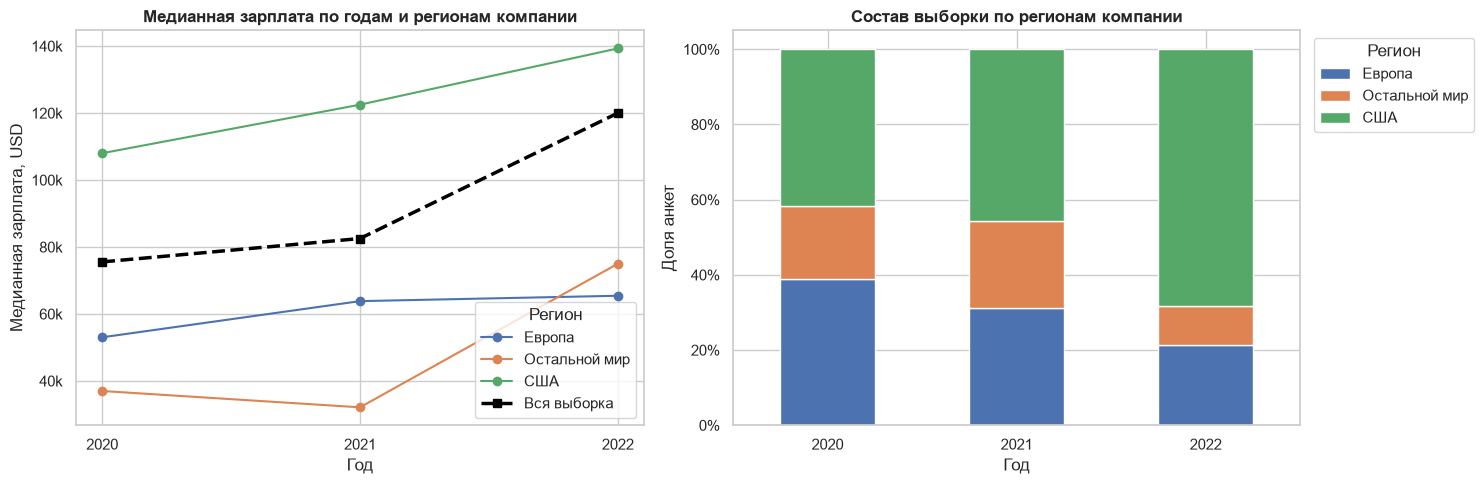

company_region,Европа,Остальной мир,США
work_year,,,
2020,53032.0,36996.0,108000.0
2021,63831.0,32118.0,122500.0
2022,65438.0,75000.0,139300.0


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

med_year = df.groupby(['work_year', 'company_region'])['salary_in_usd'].median().unstack()
med_year.plot(marker='o', ax=axes[0])
axes[0].plot(by_year.index, by_year['медиана, USD'], marker='s', color='black', lw=2.5, ls='--', label='Вся выборка')
axes[0].set_title('Медианная зарплата по годам и регионам компании')
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Медианная зарплата, USD')
axes[0].set_xticks([2020, 2021, 2022])
axes[0].yaxis.set_major_formatter(usd_fmt)
axes[0].legend(title='Регион')

share = pd.crosstab(df['work_year'], df['company_region'], normalize='index')
share.plot(kind='bar', stacked=True, ax=axes[1], rot=0)
axes[1].set_title('Состав выборки по регионам компании')
axes[1].set_xlabel('Год')
axes[1].set_ylabel('Доля анкет')
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].legend(title='Регион', bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.show()
display(med_year.round(0))


**H5 подтверждена частично.** По всей выборке медианная зарплата выросла с 75.5 тыс. USD в 2020 году до 120 тыс. USD в 2022, и различия между годами статистически значимы. Но за эти же годы изменился состав анкет: доля компаний США и доля Senior с Executive заметно выросли. Выше я показал, что опытные сотрудники и сотрудники компаний США получают больше остальных. Поэтому медиана по всей выборке поднялась бы и при неизменных зарплатах, только за счёт роста доли этих групп.


Чтобы отделить рост зарплат от смены состава, я сравнил анкеты с одинаковым опытом и страной компании. Единой картины там нет: у Junior и Middle медиана выросла, у Senior снизилась, а статистически значимо изменение только в одной группе из шести, у Middle вне США. 

На графике медиана растёт в каждом регионе, хотя внутри групп с одинаковым опытом роста почти нет. Значит, страна компании рост не объясняет, и основной вклад даёт увеличение доли опытных сотрудников.


## 5. Визуализация данных



### 5.1. Боксплоты: зарплата по ключевым факторам

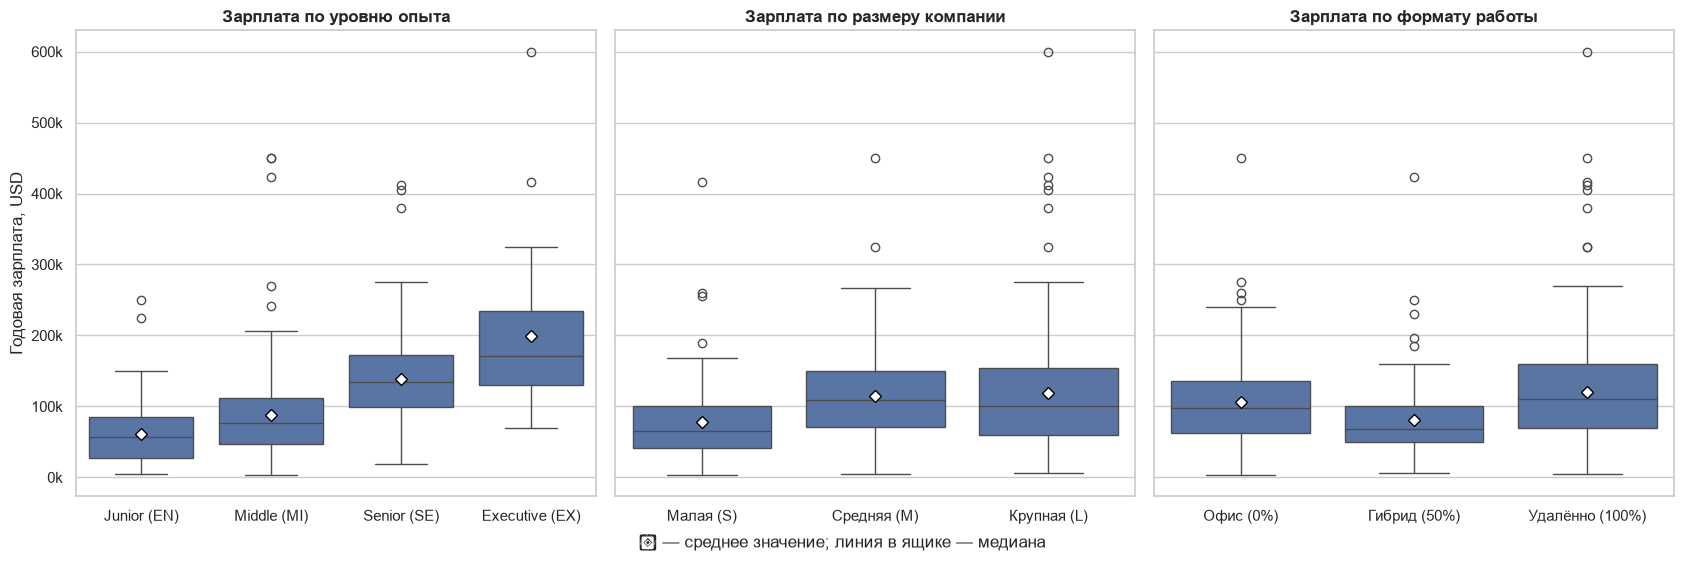

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)
for ax, (col, title) in zip(axes, [('experience', 'по уровню опыта'),
                                   ('size', 'по размеру компании'),
                                   ('remote', 'по формату работы')]):
    sns.boxplot(data=df, x=col, y='salary_in_usd', color=MAIN_COLOR, ax=ax, showmeans=True,
                meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black'})
    ax.set_title(f'Зарплата {title}')
    ax.set_xlabel('')
    ax.set_ylabel('Годовая зарплата, USD')
    ax.yaxis.set_major_formatter(usd_fmt)
fig.text(0.5, -0.01, '◇ — среднее значение; линия в ящике — медиана', ha='center')
plt.tight_layout()
plt.show()

С ростом опыта ящик целиком сдвигается вверх: у Junior и Senior они не пересекаются, то есть три четверти Junior получают меньше, чем нижняя четверть Senior. По размеру компании отличается только малая, у средних и крупных медианы близки. По формату работы ниже остальных гибрид, что в 4.5 объяснилось малой долей компаний США в этой группе.

На всех трёх графиках среднее лежит выше медианы, а выбросы есть только сверху (правоскошенное распределение)

### 5.2. Violin plot: зарплата по категориям должностей


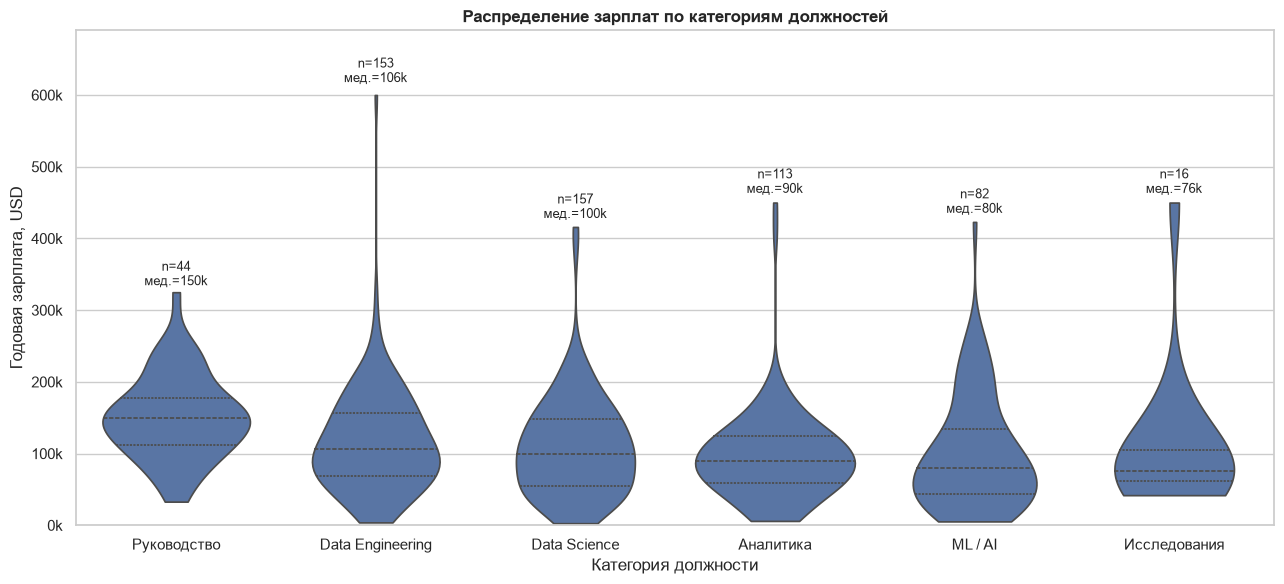

In [40]:
order = df.groupby('job_category')['salary_in_usd'].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(13, 6))
sns.violinplot(data=df, x='job_category', y='salary_in_usd', order=order, color=MAIN_COLOR,
               inner='quartile', cut=0, ax=ax)
for i, cat in enumerate(order):
    sub = df.loc[df.job_category == cat, 'salary_in_usd']
    ax.text(i, sub.max() * 1.03, f'n={len(sub)}\nмед.={sub.median()/1000:.0f}k', ha='center', fontsize=9)
ax.set_title('Распределение зарплат по категориям должностей')
ax.set_xlabel('Категория должности')
ax.set_ylabel('Годовая зарплата, USD')
ax.yaxis.set_major_formatter(usd_fmt)
ax.set_ylim(0, df['salary_in_usd'].max() * 1.15)
plt.tight_layout()
plt.show()

Руководство отличается от остальных не только медианой, но и формой: распределение поднято целиком, низких зарплат в нём почти нет. У остальных категорий основная масса анкет лежит ниже 100 тыс. USD, а вверх уходит длинный тонкий хвост.

У ML/AI самый большой разброс: много анкет внизу и заметная доля высоких зарплат. Это согласуется с выводом по H6, где внутри этой категории смешаны компании США и остальных стран.

### 5.3. Heatmap: медианная зарплата в разрезе «опыт × регион компании»


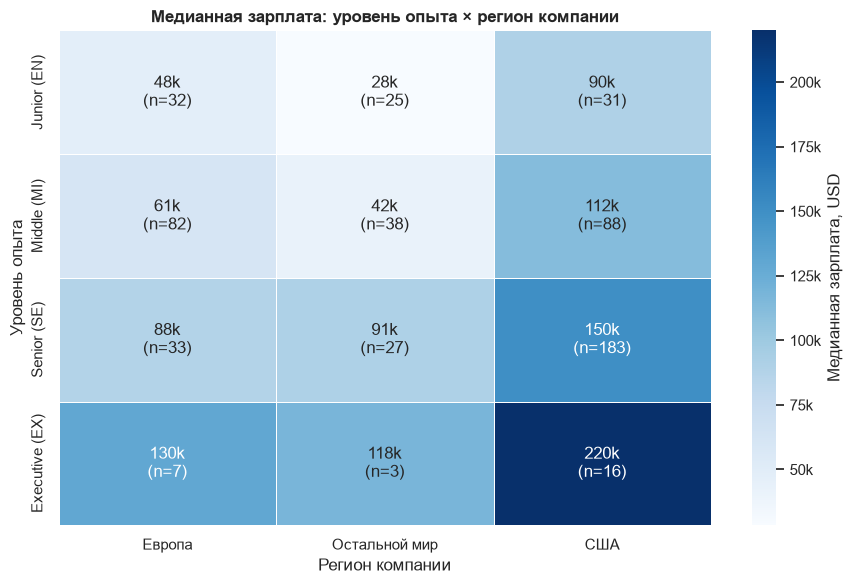

In [41]:
pivot = df.pivot_table(index='experience', columns='company_region', values='salary_in_usd',
                       aggfunc='median', observed=True)
counts = df.pivot_table(index='experience', columns='company_region', values='salary_in_usd',
                        aggfunc='count', observed=True)
annot = pivot.map(lambda v: f'{v/1000:.0f}k') + counts.map(lambda n: f'\n(n={n})')

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(pivot, annot=annot, fmt='', cmap='Blues', linewidths=0.5,
            cbar_kws={'label': 'Медианная зарплата, USD', 'format': usd_fmt}, ax=ax)
ax.set_title('Медианная зарплата: уровень опыта × регион компании')
ax.set_xlabel('Регион компании')
ax.set_ylabel('Уровень опыта')
plt.tight_layout()
plt.show()

### 5.4. Scatter plot: страны компаний - число анкет и медианная зарплата

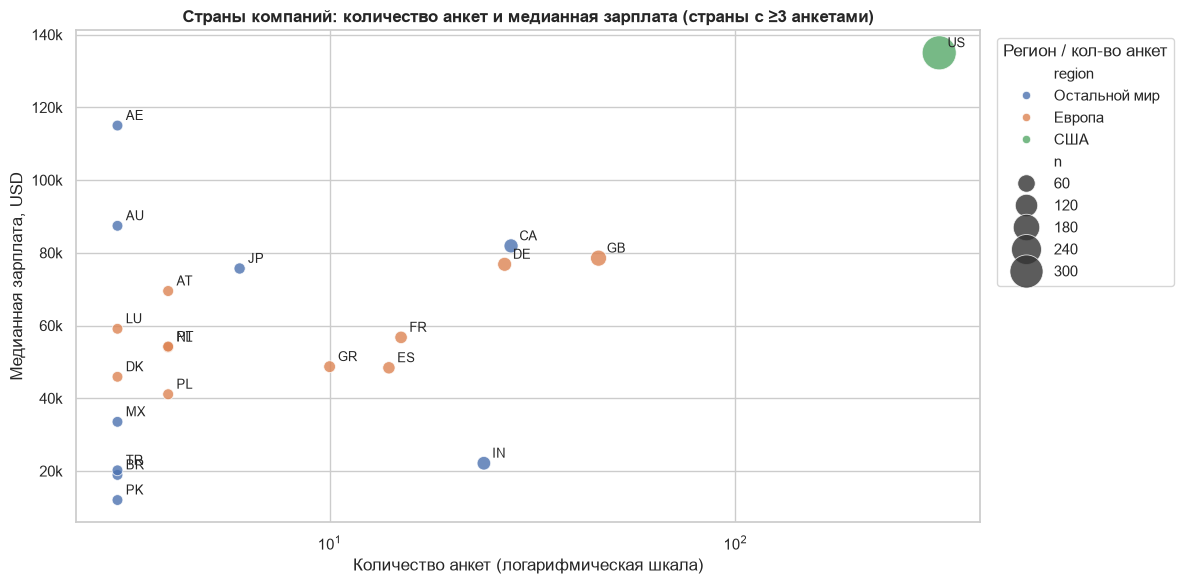

In [42]:
country = (df.groupby('company_location')
             .agg(n=('salary_in_usd', 'size'), median_salary=('salary_in_usd', 'median'),
                  region=('company_region', 'first'))
             .query('n >= 3'))
country = country.assign(Регион=country['region'], Анкет=country['n'])


fig, ax = plt.subplots(figsize=(12, 6))
sns.scatterplot(data=country, x='n', y='median_salary', hue='region', size='n', sizes=(60, 600),
                alpha=0.8, ax=ax, legend='brief')
for code_, row in country.iterrows():
    ax.annotate(code_, (row['n'], row['median_salary']), xytext=(6, 4), textcoords='offset points', fontsize=9)
ax.set_xscale('log')
ax.set_title('Страны компаний: количество анкет и медианная зарплата (страны с ≥3 анкетами)')
ax.set_xlabel('Количество анкет (логарифмическая шкала)')
ax.set_ylabel('Медианная зарплата, USD')
ax.yaxis.set_major_formatter(usd_fmt)
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', title='Регион / кол-во анкет')
plt.tight_layout()
plt.show()

США стоят отдельно в правом верхнем углу: это и самая многочисленная страна, и страна с самой высокой медианой. Следом идут Великобритания, Германия и Канада с близкими между собой медианами. Индия при сопоставимом с ними числе анкет находится в самом низу.

Слева, у стран с 3-5 анкетами, разброс медиан самый большой. Это следствие малого числа анкет,сравнивать эти страны между собой я не стал
### 5.5. Scatter plot: зарплата по годам и уровню опыта

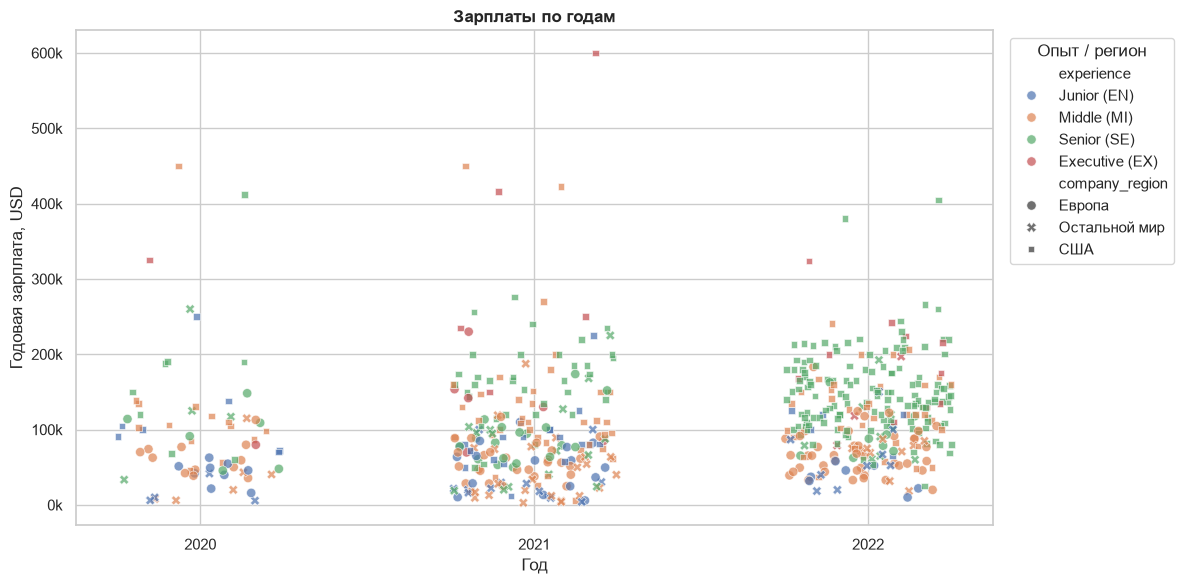

In [43]:
fig, ax = plt.subplots(figsize=(12, 6))
jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.25, 0.25, len(df))
sns.scatterplot(x=df['work_year'] + jitter, y=df['salary_in_usd'], hue=df['experience'],
                style=df['company_region'], alpha=0.7, s=45, ax=ax)
ax.set_xticks([2020, 2021, 2022])
ax.set_title('Зарплаты по годам')
ax.set_xlabel('Год')
ax.set_ylabel('Годовая зарплата, USD')
ax.yaxis.set_major_formatter(usd_fmt)
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', title='Опыт / регион')
plt.tight_layout()
plt.show()

В 2022 году точек больше всего, и основная их масса - Senior из компаний США в диапазоне от 100 до 220 тыс. USD. В 2020 году анкет мало, и в них преобладают Junior и Middle. Нижняя часть графика во все три года занята теми же группами: Junior и Middle вне США.

То есть облако поднялось не потому, что те же группы стали получать больше, а потому, что в нём стало больше высокооплачиваемых анкет. Это наглядно подтверждает вывод по H5 о смене состава выборки.

### Выводы по визуализации

Я построил боксплоты, violin plot, тепловую карту и два точечных графика. На каждом из них видны одни и те же два фактора: уровень опыта и расположение компании в США. Размер компании, формат работы и категория должности дают повышение в зарплат, но гораздо слабее, и большая часть зарплат объясняется долей компаний США в группе.


## 6. Прогнозирование и моделирование

**Задача регрессии:** предсказать годовую зарплату `salary_in_usd` по характеристикам анкеты. Цель моделирования заключается не столько в точном прогнозе, сколько в **оценке важности факторов** при прочих равных и ответить на вопрос о топ-3 факторах.

**Целевая переменная:** `log_salary`. Логарифм снижает влияние выбросов и коэффициенты линейной модели интерпретируются/читаются как изменение запралвты в процентах («опыт увеличивает зарплату на X%»), что лучше соответствует природе зарплат. Метрики считаем после обратного преобразования в долларах.

### 6.1. Подготовка признаков

| Признаки | Преобразование |
|---|---|
| `work_year`, `exp_level_num`, `company_size_num`, `remote_ratio`, `abroad` | Стандартизация |
| `company_region`, `job_category`, `employment_type` | One-hot Кодирование |

One-Hot создаёт для каждой категории отдельный бинарный столбец, тем самым модель не будет считать категории упорядоченными. Используем укрупнённые признаки (`company_region`, `job_category`), вместо 50 должностей и 50 стран, чтобы не получить сотни редких столбцов на 565 строках.
  

- Также проводим **`стандартизацию количественных признаков`** для линейных моделей. Без неё веса признаков разного масштаба несопоставимы и их сложнее интерпретировать. Кроме того, регуляризация L1 и L2 не учитывает масштаб признака. Признаку с маленькими значениями нужен большой вес, и регуляризация штрафует его сильнее, чем признак с большими значениями и маленьким весом.

Кодирование и стандартизация обучаются внутри `Pipeline` только на обучающей выборке, поэтому информация из теста в модель не попадает.




In [52]:
from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

num_features = ['work_year', 'exp_level_num', 'company_size_num', 'remote_ratio', 'abroad']
cat_features = ['company_region', 'job_category', 'employment_type']

X = df[num_features + cat_features]
y = df['log_salary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=df['experience_level'])
print(f'Обучающая выборка: {X_train.shape}, тестовая: {X_test.shape}')

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_features),
])

Обучающая выборка: (452, 8), тестовая: (113, 8)


Разбиение 80/20 **стратифицировано по уровню опыта**, чтобы редкая группа Executive была и в обучении, и в тесте.

### 6.2. Модели и кросс-валидация

Я сравниваю шесть моделей: прогноз медианой как точку отсчёта, линейную регрессию, Ridge, Lasso дерево решений, случайный лес и градиентный бустинг. Глубину деревьев и размер листа я ограничил, потому что на `452` строках без ограничений деревья переобучаются. Коэффициент регуляризации для Ridge и Lasso подбирается внутренней кросс-валидацией.

Модели предсказывают логарифм зарплаты, поэтому перед расчётом ошибки я перевожу прогноз и факт обратно в доллары экспонентой: $e^{\ln x} = x$.

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import make_scorer
from catboost import CatBoostRegressor

models = {
    'Baseline (медиана)': DummyRegressor(strategy='median'),
    'Linear Regression': LinearRegression(),
    'Ridge': RidgeCV(alphas=np.logspace(-3, 3, 13), cv=5),
    'Lasso': LassoCV(cv=5, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeRegressor(max_depth=5, min_samples_leaf=10, random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                           random_state=RANDOM_STATE, n_jobs=-1),
    'CatBoost': CatBoostRegressor(iterations=500, learning_rate=0.05, depth=4,
                                  random_seed=RANDOM_STATE, verbose=0),
}

def usd_mae(y_true, y_pred):
    return mean_absolute_error(np.exp(y_true), np.exp(y_pred))

scoring = {'mae_usd': make_scorer(usd_mae, greater_is_better=False), 'r2_log': 'r2'}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = []
fitted = {}
for name, model in models.items():
    prep = 'passthrough' if name == 'CatBoost' else preprocessor
    pipe = Pipeline([('prep', prep), ('model', model)])
    fit_params = {'model__cat_features': cat_features} if name == 'CatBoost' else {}
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, params=fit_params)
    pipe.fit(X_train, y_train, **fit_params)
    fitted[name] = pipe
    pred = np.exp(pipe.predict(X_test))
    true = np.exp(y_test)
    results.append({
        'модель': name,
        'CV MAE, USD': -cv_res['test_mae_usd'].mean(),
        'CV MAE std': cv_res['test_mae_usd'].std(),
        'CV R² (log)': cv_res['test_r2_log'].mean(),
        'Test MAE, USD': mean_absolute_error(true, pred),
        'Test RMSE, USD': np.sqrt(mean_squared_error(true, pred)),
        'Test R² (USD)': r2_score(true, pred),
    })

ridge, lasso = fitted['Ridge'].named_steps['model'], fitted['Lasso'].named_steps['model']
print(f'Ridge: alpha = {ridge.alpha_:.4f}')
print(f'Lasso: alpha = {lasso.alpha_:.4f}, обнулено коэффициентов: {(lasso.coef_ == 0).sum()} из {lasso.coef_.size}')

results_df = pd.DataFrame(results).set_index('модель').round(3)
results_df.style.format({c: '{:,.0f}' for c in ['CV MAE, USD', 'CV MAE std', 'Test MAE, USD', 'Test RMSE, USD']}
                        | {c: '{:.3f}' for c in ['CV R² (log)', 'Test R² (USD)']})

Ridge: alpha = 1.0000
Lasso: alpha = 0.0019, обнулено коэффициентов: 0 из 15


,"CV MAE, USD",CV MAE std,CV R² (log),"Test MAE, USD","Test RMSE, USD",Test R² (USD)
модель,,,,,,
Baseline (медиана),"53,245","2,729",-0.032,"51,473","72,675",-0.222
Linear Regression,"36,206","2,806",0.498,"37,519","56,192",0.270
Ridge,"35,939","2,851",0.499,"37,863","57,090",0.246
Lasso,"35,754","2,819",0.498,"37,984","57,314",0.240
Decision Tree,"36,688","3,087",0.429,"37,065","56,381",0.265
Random Forest,"36,160","2,926",0.477,"34,944","54,259",0.319
CatBoost,"35,791","2,948",0.524,"36,112","54,500",0.313


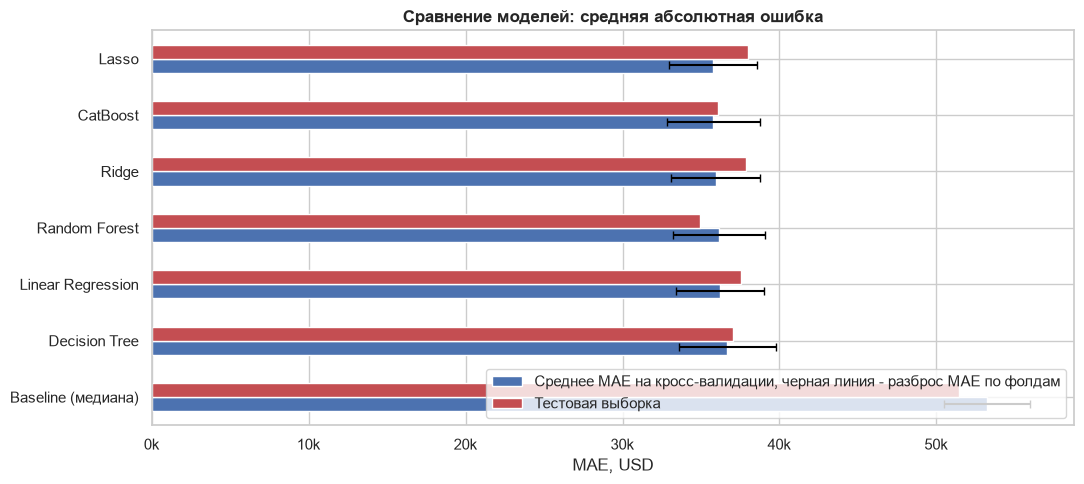

In [59]:
fig, ax = plt.subplots(figsize=(11, 5))
plot_df = results_df[['CV MAE, USD', 'Test MAE, USD']].sort_values('CV MAE, USD', ascending=False)
plot_df.plot(kind='barh', ax=ax, color=[MAIN_COLOR, ACCENT_COLOR])
ax.errorbar(plot_df['CV MAE, USD'], np.arange(len(plot_df)) - 0.12,
            xerr=results_df.loc[plot_df.index, 'CV MAE std'], fmt='none', ecolor='black', capsize=3)
ax.set_title('Сравнение моделей: средняя абсолютная ошибка')
ax.set_xlabel('MAE, USD')
ax.set_ylabel('')
ax.xaxis.set_major_formatter(usd_fmt)
ax.legend(['Среднее MAE на кросс-валидации, черная линия - разброс MAE по фолдам', 'Тестовая выборка'], loc='lower right')
plt.tight_layout()
plt.show()

### 6.3. Важность признаков

Я по очереди перемешиваю значения одного признака в тестовой выборке и смотрю, насколько падает R². Так оценивается важность исходного признака целиком, а не отдельных one-hot столбцов.

Лучшая модель по кросс-валидации: Lasso


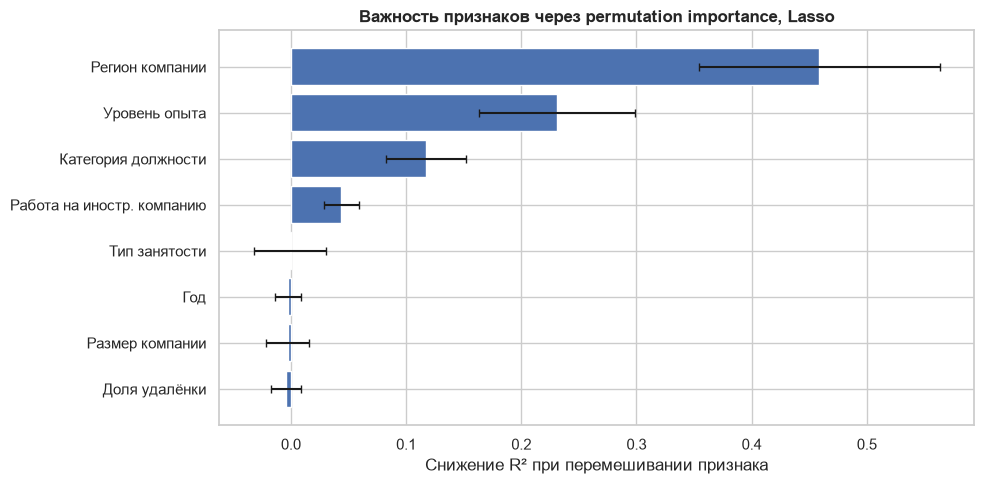

,importance,std
Регион компании,0.459,0.105
Уровень опыта,0.231,0.067
Категория должности,0.117,0.035
Работа на иностр. компанию,0.044,0.015
Тип занятости,-0.001,0.031
Год,-0.002,0.012
Размер компании,-0.003,0.019
Доля удалёнки,-0.004,0.013


In [62]:
best_name = results_df['CV MAE, USD'].idxmin()
print(f'Лучшая модель по кросс-валидации: {best_name}')

FEATURE_LABELS = {'work_year': 'Год', 'exp_level_num': 'Уровень опыта', 'company_size_num': 'Размер компании',
                  'remote_ratio': 'Доля удалёнки', 'abroad': 'Работа на иностр. компанию',
                  'company_region': 'Регион компании', 'job_category': 'Категория должности',
                  'employment_type': 'Тип занятости'}

perm = permutation_importance(fitted[best_name], X_test, y_test, n_repeats=30,
                              random_state=RANDOM_STATE, scoring='r2')
imp = (pd.DataFrame({'importance': perm.importances_mean, 'std': perm.importances_std}, index=X.columns)
         .rename(index=FEATURE_LABELS).sort_values('importance'))

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(imp.index, imp['importance'], xerr=imp['std'], color=MAIN_COLOR, capsize=3)
ax.set_title(f'Важность признаков через permutation importance, {best_name}')
ax.set_xlabel('Снижение R² при перемешивании признака')
plt.tight_layout()
plt.show()
imp.sort_values('importance', ascending=False).round(3)

Модель опирается на три признака: регион компании, уровень опыта и категорию должности. Работа на иностранную компанию даёт вклад, хоть и меньше по сравнению с топ-3. У года анкеты, размера компании, доли удалёнки и типа занятости важность около нуля, и разброс перекрывает ноль.

### 6.4. Интерпретация линейной модели (statsmodels)

Для каждого признака линейная регрессия на логарифме зарплаты даёт эффект $e^{\beta} - 1$, то есть изменение зарплаты в процентах при прочих равных. Модель я строю в `statsmodels`, потому что он даёт для эффектов p-value и доверительные интервалы. Стандартные ошибки робастные, HC3, потому что разброс зарплат в группах разный.

Модель построена только на полной занятости FT, группы PT, CT и FL слишком малы. Эффекты считаются относительно следующих базовых категорий: Middle, Data Science, Европа, средняя компания, офис, 2020 год.

In [ ]:
import statsmodels.formula.api as smf

ols = smf.ols(
    'log_salary ~ C(experience_level, Treatment("MI")) + C(company_region, Treatment("Европа"))'
    ' + C(company_size, Treatment("M")) + C(remote_ratio) + C(job_category, Treatment("Data Science"))'
    ' + C(work_year) + abroad',
    data=df[df.employment_type == 'FT']
).fit(cov_type='HC3') # для робастности данных, потому что ошибка модели для США, Европы и остального мира разная, поэтому чтобы не занижать стандартные ошибки, используем формулу НСЗ

coef = pd.DataFrame({
    'коэф.': ols.params,
    'эффект, %': (np.exp(ols.params) - 1) * 100,
    'p-value': ols.pvalues,
    'CI 2.5%, %': (np.exp(ols.conf_int()[0]) - 1) * 100,
    'CI 97.5%, %': (np.exp(ols.conf_int()[1]) - 1) * 100,
}).drop('Intercept')
coef.index = (coef.index.str.replace(r'C\((\w+).*?\)\[T\.(.+)\]', r'\1 = \2', regex=True))
print(f'R² = {ols.rsquared:.3f}, скорр. R² = {ols.rsquared_adj:.3f}, наблюдений = {int(ols.nobs)} (только FT)')
coef.round(3)

R² = 0.514, скорр. R² = 0.498, наблюдений = 546


,коэф.,"эффект, %",p-value,"CI 2.5%, %","CI 97.5%, %"
experience_level = EN,-0.255,-22.495,0.008,-35.811,-6.417
experience_level = EX,0.710,103.333,0.000,67.530,146.786
experience_level = SE,0.339,40.419,0.000,25.476,57.142
company_region = Остальной мир,-0.337,-28.603,0.001,-41.933,-12.213
company_region = США,0.591,80.551,0.000,60.430,103.195
company_size = L,0.115,12.240,0.081,-1.431,27.807
company_size = S,-0.080,-7.656,0.464,-25.374,14.269
remote_ratio = 50,0.071,7.380,0.480,-11.854,30.811
remote_ratio = 100,0.069,7.151,0.289,-5.696,21.748
job_category = Data Engineering,-0.017,-1.700,0.784,-13.040,11.119


Модель объясняет около половины разброса логарифма зарплаты.

- Значимы страна компании и опыт. Компании США платят на 81% больше европейских при том же опыте и той же должности, остальной мир - на 29% меньше. Senior получает на 40% больше Middle, Executive - примерно вдвое больше.
- Из категорий должностей значимо отличается только аналитика, она на 22% ниже Data Science. Надбавка руководству при учёте опыта и страны становится незначимой. Значит, высокая медиана руководителей в H6 связана в основном с их опытом и страной, а не с самой должностью.
- Размер компании, формат работы и год анкеты незначимы. Для формата и года это совпадает с выводами по H4 и H5. Малые компании в модели тоже значимо не отличаются от средних, значит разница в H3 объясняется другими признаками этих компаний, а не размером.
- Работа на иностранную компанию снижает зарплату на 23% при той же стране компании. Возможно, что такие сотрудники получают по рынку страны проживания.

### 6.5. Анализ ошибок лучшей модели

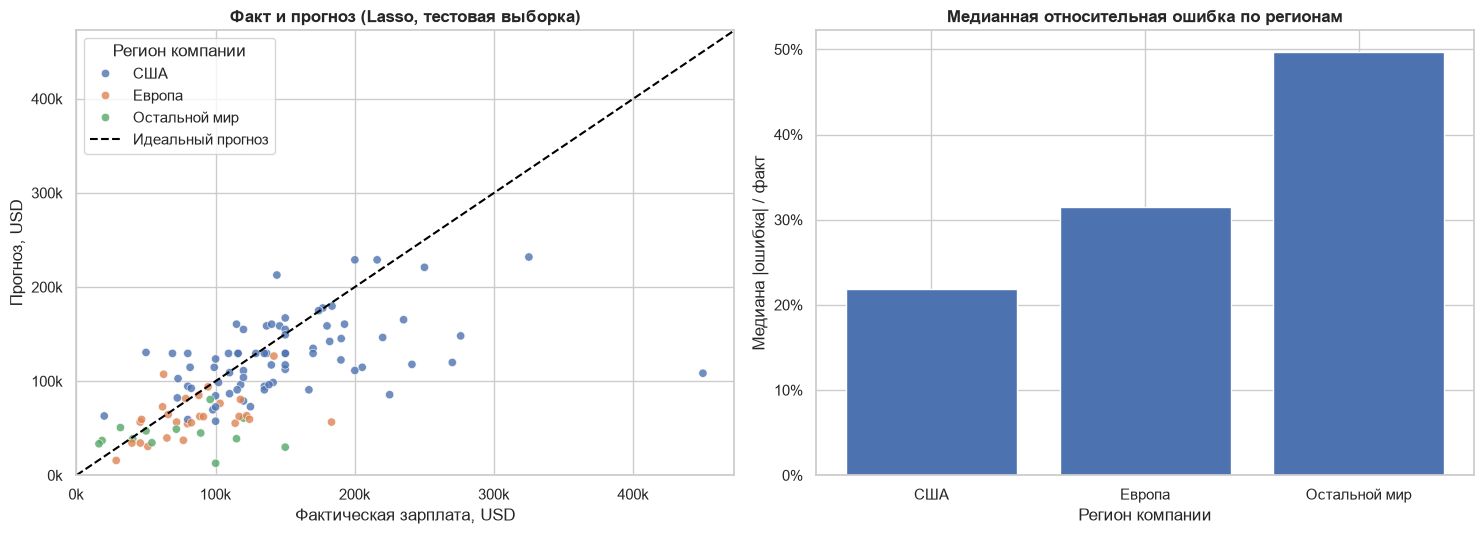

Медианная относительная ошибка: 26.0%

Топ-5 анкет с наибольшей ошибкой:


,exp_level_num,company_region,job_category,true,pred
33,2,США,Исследования,450000.0,108419.152995
78,2,США,ML / AI,270000.0,119834.570015
115,1,США,ML / AI,225000.0,85619.557516
93,3,США,Data Engineering,276000.0,148056.617039
453,2,Европа,Data Science,183228.0,56523.942340


In [69]:
best = fitted[best_name]
test = X_test.copy()
test['true'] = np.exp(y_test)
test['pred'] = np.exp(best.predict(X_test))
test['abs_err'] = (test['true'] - test['pred']).abs()
test['rel_err'] = test['abs_err'] / test['true']

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(data=test, x='true', y='pred', hue='company_region', alpha=0.8, ax=axes[0])
lim = [0, test[['true', 'pred']].max().max() * 1.05]
axes[0].plot(lim, lim, ls='--', color='black', label='Идеальный прогноз')
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_title(f'Факт и прогноз ({best_name}, тестовая выборка)')
axes[0].set_xlabel('Фактическая зарплата, USD')
axes[0].set_ylabel('Прогноз, USD')
axes[0].xaxis.set_major_formatter(usd_fmt); axes[0].yaxis.set_major_formatter(usd_fmt)
axes[0].legend(title='Регион компании')

err = test.groupby('company_region')['rel_err'].median().sort_values()
axes[1].bar(err.index, err.values, color=MAIN_COLOR)
axes[1].set_title('Медианная относительная ошибка по регионам')
axes[1].set_xlabel('Регион компании')
axes[1].set_ylabel('Медиана |ошибка| / факт')
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

print(f"Медианная относительная ошибка: {test['rel_err'].median():.1%}")
print('\nТоп-5 анкет с наибольшей ошибкой:')
test.sort_values('abs_err', ascending=False).head(5)[['exp_level_num', 'company_region', 'job_category', 'true', 'pred']]

Модель занижает высокие зарплаты: почти все точки с фактом выше 200 тыс. USD лежат ниже диагонали, а прогноз не поднимается выше 230 тыс. USD. Модели известны только опыт, страна и должность, поэтому для любой анкеты она предсказывает типичную зарплату её группы. Признаков, которые отличали бы высокую зарплату от остальных в той же группе, в данных нет. Вторая причина в логарифме: экспонента от прогноза даёт медиану зарплаты в группе, а при правом хвосте медиана ниже среднего.

Вне США ошибка выше всего, для остального мира она примерно вдвое больше, чем для США. В «Остальной мир» объединены страны с очень разным уровнем зарплат, от Индии до ОАЭ, что видно на графике 5.4, и одним регионом их не описать.

### Выводы по моделированию

- Я сравнил шесть моделей. Все снижают ошибку относительно прогноза медианой примерно на треть, а между собой по качеству неразличимы, поэтому для интерпретации я выбрал линейную модель.
- Лучшая модель объясняет около половины разброса, типичная ошибка прогноза - четверть зарплаты. Остальное зависит от признаков, которых нет в анкете.
- Важность признаков и коэффициенты регрессии дают один и тот же порядок факторов: регион компании, уровень опыта, категория должности.
- При прочих равных незначимы размер компании, формат работы, год анкеты и надбавка руководству.

## 7. Формулировка выводов

### 7.1. Какие данные и что сделано

Исследован датасет **Data Science Job Salaries** (ai-jobs.net / Kaggle) — 607 анонимных анкет специалистов по данным за 2020–2022 гг. В ходе предобработки удалено 42 полных дубликата, исключены несопоставимые столбцы зарплаты в местной валюте, выбросы, то есть 10 анкет с зарплатой >284 тыс. USD и все анкеты из компаний США, сохранены как реальный верхний сегмент рынка. Созданы укрупнённые признаки: категория должности (6 групп вместо 50 названий) и регион компании (США / Европа / Остальной мир). Итоговый набор — 565 записей.

Распределение зарплат не подчиняется законам нормального распределения (правосторонняя асимметрия ≈ 1.7, тест Шапиро–Уилка p ≪ 0.05), поэтому сравнения проводились по медианам с применением непараметрических тестов Манна–Уитни, Краскела–Уоллиса и коэффициентом Спирмена.

### 7.2. Проверка гипотез

| Гипотеза | Результат | Основание |
|---|---|---|
| H1. Зарплата растёт с уровнем опыта | подтверждена | медиана растёт на каждом уровне: `56 500` → `76 940` → `135 000` → `171 438` USD, самый большой шаг - от Middle к Senior |
| H2. Компании из США платят больше | подтверждена | `135 000` против `62 651` USD, разрыв сохраняется внутри каждого уровня опыта |
| H3. В малых компаниях зарплаты ниже | подтверждена | `65 511` против `105 000` USD в средних и крупных, средние и крупные между собой не различаются |
| H4. Удалённые сотрудники получают не меньше офисных и гибридных | подтверждена | удалённо `110 712`, офис `98 158`, гибрид `68 010` USD, внутри компаний США и внутри остальных формат на зарплату не влияет |
| H5. Зарплаты выросли с 2020 по 2022 год | подтверждена частично | по всей выборке с `75.5` до `120` тыс. USD, но рост объясняется увеличением доли опытных сотрудников, внутри групп с одинаковым опытом и страной роста почти нет |
| H6. Руководство и ML/AI оплачиваются выше аналитики | подтверждена частично | руководство `150 130` против `90 000` USD, ML/AI по всей выборке ниже аналитики, `79 896` USD, но выше её внутри одной страны: в США `144 000` против `109 640` USD |

### 7.3. Ключевые находки — топ-3 фактора зарплаты

По совокупности статистических тестов, корреляционного анализа и важности признаков в моделях:

1. **Страна (регион) компании** - фактор №1. Компании из США платят в среднем в 2+ раза больше остальных при одинаковом уровне опыта.
2. **Уровень опыта** - фактор №2. Самый большой скачок — переход **Middle → Senior (+75% по медиане)**; зависимость монотонная, нелинейная, шаги неравные.
3. **Категория должности** - фактор №3. Руководящие позиции и ML/AI оплачиваются выше, аналитические роли — ниже всех. Отрицательный по силе вклад даёт признак «работа на иностранную компанию» (такие сотрудники живут в странах с более низким уровнем зарплат).

Размер компании, формат удалённой работы и тип занятости оказывают **слабое** влияние по сравнению с этими тремя факторами.


### 7.4. Практические рекомендации

Работодателям и HR:
- Строить вилку от рынка страны компании и уровня опыта. Размер компании и формат работы для вилки не важны.
- Не снижать оплату за удалённую работу: внутри одной страны удалённые сотрудники получают не меньше офисных.

Соискателям:
- Больше всего доход увеличивают переход с Middle на Senior и работа на компанию из США.
- Переход из аналитики в Data Science, Data Engineering или ML даёт прибавку при том же опыте и в той же стране.


